In [ ]:
import sys
print(sys.executable)

/usr/bin/python3


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from huggingface_hub import login
login()

In [ ]:
!{sys.executable} -m pip install nibabel
!{sys.executable} -m pip install pandas
!{sys.executable} -m pip install matplotlib
!{sys.executable} -m pip install numpy
!{sys.executable} -m pip install openpyxl
!{sys.executable} -m pip install pathlib
!{sys.executable} -m pip install --no-cache-dir pyarrow==21.0.0 datasets==4.0.0
!{sys.executable} -m pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu118

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.8/42.8 MB 50.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 494.8/494.8 kB 367.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.3/116.3 kB 318.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 193.6/193.6 kB 320.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 146.7/146.7 kB 333.3 MB/s eta 0:00:00
  Attempting uninstall: pyarrow
    Found existing installation: pyarrow 23.0.1
    Uninstalling pyarrow-23.0.1:
      Successfully uninstalled pyarrow-23.0.1
  Attempting uninstall: fsspec
    Found existing installation: fsspec 2025.12.0
    Uninstalling fsspec-2025.12.0:
      Successfully uninstalled fsspec-2025.12.0
  Attempting uninstall: dill
    Found existing installation: dill 0.4.1
    Uninstalling dill-0.4.1:
      Successfully uninstalled dill-0.4.1
  Attempting uninstall: multiprocess
    Found existing installation: multiprocess 0.70.19
    Uninstalling multiprocess-0.70.19:


In [ ]:
!pip install -U torchao transformers accelerate peft bitsandbytes

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 114.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.3/12.3 MB 150.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 394.3/394.3 kB 38.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 832.9/832.9 kB 65.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 63.5 MB/s eta 0:00:00
  Attempting uninstall: torchao
    Found existing installation: torchao 0.10.0
    Uninstalling torchao-0.10.0:
      Successfully uninstalled torchao-0.10.0
  Attempting uninstall: transformers
    Found existing installation: transformers 5.16.1
    Uninstalling transformers-5.16.1:
      Successfully uninstalled transformers-5.16.1
  Attempting uninstall: accelerate
    Found existing installation: accelerate 1.14.0
    Uninstalling accelerate-1.14.0:
      Successfully uninstalled accelerate-1.14.0
  Attempting uninstall: peft
    Found existing installation: peft 0.20.0
    Uninstalling p

In [ ]:
from PIL import Image
import requests
import torch
from pathlib import Path
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import os
import random as r
import matplotlib.patches as patches
from ipywidgets import interact
import textwrap
import json
from PIL import ImageDraw, ImageFont
import pyarrow
import datasets
import pandas
from datasets import Dataset, DatasetDict


Task 1: Slide Division to pass series with corresponding masks

In [ ]:
duke_nifti_folder_path = r'/content/drive/MyDrive/Duke_Dataset/BreastDCEDL_duke/BreastDCEDL_duke/duke_subset_nii/Duke_subset_vol'
finetuned_breast_mask = r'/content/drive/MyDrive/Duke_Dataset/BreastDCEDL_duke/BreastDCEDL_duke/duke_subset_nii/Breask_mask_pred'

post_contrast_paths = []
patient_ids = []
predicted_segmentation_mask =[] # acting as ground truth for now
tumor_annotation_boxes = []
#percent_enhancement_1_paths = []

#iterate - standerdized/1 center so shouldnt have to check tm
for patient_folder in Path(duke_nifti_folder_path).iterdir():
  #print(patient_folder)
  pid = patient_folder.name
  all_found = False
  pc_found = False
  ps_found = False
  tab_found=False
  for subfolder in patient_folder.iterdir():
      if subfolder.name == 'd2n_post.nii.gz':
          post_contrast_paths.append(subfolder) #pc1
          pc_found = True
      if subfolder.name == 'predicted_tumor_mask.nii.gz':
          predicted_segmentation_mask.append(subfolder) # seg mask
          ps_found = True
      if subfolder.name == 'tumor_box.nii.gz':
          tumor_annotation_boxes.append(subfolder) # annotation box
          tab_found = True
      # if subfolder.name == 'pe1.nii.gz':
      #     percent_enhancement_1_paths.append(subfolder)
  if(pc_found and ps_found and tab_found):
    patient_ids.append(pid)
  else:
    if pc_found:
      post_contrast_paths = post_contrast_paths[:-1]
    if ps_found:
      predicted_segmentation_mask = predicted_segmentation_mask[:-1]
    if tab_found:
      tumor_annotation_boxes = tumor_annotation_boxes[:-1]

print(len(patient_ids))
print(len(post_contrast_paths))
print(len(predicted_segmentation_mask))
print(len(tumor_annotation_boxes))

volume_path_df = pd.DataFrame({
    'Patient ID': patient_ids,
    'Post Contrast 1' :post_contrast_paths,
    'Tumor Segmentation Mask' : predicted_segmentation_mask,
    'Annotation Box' : tumor_annotation_boxes,
    #'PE 1' : percent_enhancement_1_paths
    })

#get Breast Masks
bm_pid = []
bm_mask_path = []
for bm in Path(finetuned_breast_mask).iterdir():
    pid = bm.name[:14]
    bm_pid.append(pid)
    bm_mask_path.append(bm)

bm_path_df = pd.DataFrame({
    'Breast Mask Path': bm_mask_path,
    'Patient ID': bm_pid,
    })

volume_path_df = volume_path_df.merge(bm_path_df, on = 'Patient ID')

369
369
369
369


In [ ]:
subset = volume_path_df#.sample(n=100, random_state=42)

subset

,Patient ID,Post Contrast 1,Tumor Segmentation Mask,Annotation Box,Breast Mask Path
0,Breast_MRI_001,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/drive/MyDrive/Duke_Dataset/BreastDCED...
1,Breast_MRI_100,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/drive/MyDrive/Duke_Dataset/BreastDCED...
2,Breast_MRI_098,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/drive/MyDrive/Duke_Dataset/BreastDCED...
3,Breast_MRI_093,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/drive/MyDrive/Duke_Dataset/BreastDCED...
4,Breast_MRI_092,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/drive/MyDrive/Duke_Dataset/BreastDCED...
...,...,...,...,...,...
363,Breast_MRI_369,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/drive/MyDrive/Duke_Dataset/BreastDCED...
364,Breast_MRI_368,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/drive/MyDrive/Duke_Dataset/BreastDCED...
365,Breast_MRI_377,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/drive/MyDrive/Duke_Dataset/BreastDCED...
366,Breast_MRI_366,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/drive/MyDrive/Duke_Dataset/BreastDCED...


Dataset and Report Loading

In [ ]:
annotation_boxes = pd.read_excel(r'/content/drive/MyDrive/Duke_Dataset/BreastDCEDL_duke/BreastDCEDL_duke/duke_subset_nii/Duke_Features/Annotation_Boxes.xlsx')


imaging_features = pd.read_excel(r'/content/drive/MyDrive/Duke_Dataset/BreastDCEDL_duke/BreastDCEDL_duke/duke_subset_nii/Duke_Features/Imaging_Features.xlsx')
#PREDICT IMAGING FEATURES

print(imaging_features.shape)
#imaging_features.head()
# for i in imaging_features.columns:   ##All imaging Features Included
#     print(i)

#Imaging Features Filter:
imaging_features_keep = ['Patient ID',
                         'Time_to_Peak_from_char_curv',
                         'Uptake_rate_from_char_curv' ,
                         'Washout_rate_from_char_curv',
                         'Max_Enhancement_from_char_curv',
                         'Volume_cu_mm_Tumor',
                         'TumorMajorAxisLength_mm']


(922, 530)


In [ ]:
clinical_features = pd.read_excel(r'/content/drive/MyDrive/Duke_Dataset/BreastDCEDL_duke/BreastDCEDL_duke/duke_subset_nii/Duke_Features/Clinical_and_Other_Features (1).xlsx')
clinical_features.head()
clinical_features.columns = clinical_features.iloc[0] # first row is col header
clinical_features_col_descriptions = clinical_features.iloc[0] #describe what each features is (need to correplate and pass each as key)
clinical_features = clinical_features[2:]               #
clinical_features = clinical_features.reset_index(drop=True)


#likely will remove feature
birad_densities_original = pd.read_excel(r'/content/drive/MyDrive/Duke_Dataset/BreastDCEDL_duke/BreastDCEDL_duke/duke_subset_nii/Duke_Features/Breast_Radiologist_Density_Assessments.xlsx')

birad_densities = birad_densities_original[['Subject_ID', 'Radiologist A', 'Radiologist B', 'Radiologist C']]
birad_key = {
        "a": "Almost entirely fat",
        "b": "Scattered fibroglandular tissue",
        "c": "Heterogeneous fibroglandular tissue",
        "d": "Extreme fibroglandular tissue"
}
print(birad_densities.shape) # ONLY AVAILABLE FOR 50
birad_densities.head()

birad_d_mapped = birad_densities
birad_d_mapped["Radiologist A"] = birad_densities["Radiologist A"].map(birad_key)
birad_d_mapped["Radiologist B"] = birad_densities["Radiologist B"].map(birad_key)
birad_d_mapped["Radiologist C"] = birad_densities["Radiologist C"].map(birad_key)


birad_d_mapped.head()

metadata = pd.read_csv(r'/content/drive/MyDrive/Duke_Dataset/BreastDCEDL_duke/BreastDCEDL_duke/duke_subset_nii/Duke_Features/BreastDCEDL_metadata_min_crop.csv')
print(metadata.shape) # all of BreastDECL -> filter for duke only

duke_metadata = metadata[metadata['dataset'] == 'duke']
print(duke_metadata.shape) # slight missmatch w clinical/imaging feature data - few indexes missing


#Join by ID:
all_features = clinical_features.merge(imaging_features, on = 'Patient ID')
#leave duke metadata and birad unattached for now

(50, 4)


/tmp/ipykernel_580/1792298655.py:23: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  birad_d_mapped["Radiologist A"] = birad_densities["Radiologist A"].map(birad_key)
/tmp/ipykernel_580/1792298655.py:24: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  birad_d_mapped["Radiologist B"] = birad_densities["Radiologist B"].map(birad_key)
/tmp/ipykernel_580/1792298655.py:25: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value inste

(2070, 29)
(916, 29)


In [ ]:
#Join by ID:
all_data_unsplit = clinical_features.merge(imaging_features, on = 'Patient ID')
#leave duke metadata and birad unattached for now
duke_metadata_filtered = duke_metadata[['pid', 'pCR' ,'test']]

#filtered_cohort = full_cohort_and_features[full_cohort_and_features['Patient ID'].isin(duke_metadata_filtered['pid'])]

all_data_unsplit = all_data_unsplit.merge(duke_metadata_filtered, left_on = 'Patient ID', right_on = 'pid')

all_data_unsplit

,Patient ID,Days to MRI (From the Date of Diagnosis),Manufacturer,Manufacturer Model Name,Scan Options,Field Strength (Tesla),Patient Position During MRI,Image Position of Patient,Contrast Agent,Contrast Bolus Volume (mL),...,WashinRate_map_inverse_difference_is_homom_tissue_PostCon,WashinRate_map_inverse_difference_normalized_tissue_PostCon,WashinRate_map_inverse_difference_moment_normalized_tissue_PostCon,WashinRate_map_mean_tissue_PostCon,WashinRate_map_std_dev_tissue_PostCon,WashinRate_map_skewness_tissue_PostCon,WashinRate_map_kurtosis_tissue_PostCon,pid,pCR,test
0,Breast_MRI_001,6,2,0,5,1,0,-191.8003 X -176.1259 X 86.6065,1,15,...,0.171959,0.960359,0.996829,14.517894,20.347506,1.625870,11.406955,Breast_MRI_001,0.0,0.0
1,Breast_MRI_002,12,0,4,1,3,0,154.724 X 176.048 X 94.5771,1,NaN,...,0.177087,0.959067,0.996363,47.297950,83.909561,0.251498,5.659428,Breast_MRI_002,0.0,1.0
2,Breast_MRI_003,10,0,3,2,3,0,174.658 X 228.317 X 88.4878,1,NaN,...,0.170507,0.957527,0.995981,114.171582,129.252343,1.928743,11.554948,Breast_MRI_003,0.0,0.0
3,Breast_MRI_004,18,0,4,1,1,0,188.148 X 194.282 X 94.1832,1,NaN,...,0.177210,0.960705,0.996827,33.499175,69.164227,1.171314,8.493319,Breast_MRI_004,NaN,1.0
4,Breast_MRI_005,12,2,0,5,1,1,-173.063 X -150.7869 X 59.161,1,5,...,0.117966,0.930624,0.989135,34.406635,26.951415,0.985464,4.331451,Breast_MRI_005,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
911,Breast_MRI_918,6,0,4,1,1,0,179.537 X 165.877 X 100,4,NaN,...,0.223324,0.970250,0.997982,30.665570,65.018278,1.563114,12.928674,Breast_MRI_918,NaN,0.0
912,Breast_MRI_919,24,0,4,1,1,0,172.595 X 192.108 X 130.246,4,NaN,...,0.157804,0.953593,0.995567,19.556209,23.267576,0.463802,4.820925,Breast_MRI_919,NaN,0.0
913,Breast_MRI_920,21,2,0,5,1,1,-173.6078 X -147.4121 X 78.5315,3,5,...,0.178169,0.961318,0.996820,17.724748,18.299932,2.282520,13.460166,Breast_MRI_920,NaN,2.0
914,Breast_MRI_921,21,0,1,1,1,0,206.292 X 221.499 X 118.632,3,NaN,...,0.218098,0.968191,0.997618,149.643082,157.235282,1.318530,9.176372,Breast_MRI_921,NaN,0.0


In [ ]:
correct_margin_col = all_data_unsplit["Margin"].iloc[:,1]
#correct_margin_col.head()

#margin annotation key
margin_key = {
        0: "obscured",
        1: "ill-defined",
        2: "spiculated",
        3: "indistinct",
        4: "circumscribed",
        5: "microlobulated",
        6: "angular",
        7: "irregular",
        "NC": "NC",
        "NA": "NA"
}
all_data_unsplit['mapped_margin'] = correct_margin_col.map(margin_key)

#all_data_unsplit['mapped_margin']

all_data_unsplit['Breast_Shape'] = all_data_unsplit['Shape'].iloc[:, [1]]

all_data_unsplit['Breast_Shape']

receptor_mapping = {
            1: "Positive HER2",
            2: "Borderline HER"
        }
breast_shape_mapping = {
            2: "Lobular",
            1: "Irregular",
            0: "Oval"
        }
mol_mapping = {
            3: "Triple Negative",
            2: "HER2",
            1: "ER/PR Positive, HER2 Positive"
        }
coil_mapping = {
            0: "1.494",
            1: "1.5",
            2: "2.8936",
            3: "3"
}
volume_mapping = {
    0:"6",
    1:"7",
    2:"8",
    3:"9",
    4:"10",
    5:"11",
    6:"11.88",
    7:"12",
    8:"13",
    9:"13.6",
    10:"14",
    11:"14.5",
    12:"15",
    13:"16",
    14:"17",
    15:"18",
    16:"19",
    17:"20",
    18:"25"
}
contrast_mapping ={
    0: "GADAVIST",
    1:"MAGNEVIST",
    2:"MMAGNEVIST",
    3:"MULTIHANCE",
    4:"Name of agent not stated(but ContrastBolusAgent tag was present)",
    5:"ContrastBolusAgent Tag Absent"

}

#def getBreastFeatures(df, row_id, side):


# def WriteGroundTruthReportsVersion2(df):
#     row_idx = 0
#     for row in df.iloc:
#         patient_id = row['Patient ID']

#         #Features to include:
#         #bilateral or not -> check using if slide axis

#         #Field Strength (Tesla)
#         coil_strength = coil_mapping.get(row['Field Strength (Tesla)'])
#         volume_used = volume_mapping.get(row['Contrast Bolus Volume (mL)'])
#         agent_used = contrast_mapping.get(row['Contrast Agent'])

#         #FGT categorized for 100 - maybe auto quantify for rest

#         left_breast_features =[]
#         right_breast_features = []
#         bilateral = True if row['Bilateral Information'] == 1 else False

#         if bilateral:




#         gt_report == f"""
#         GROUND TRUTH REPORT FOR {patient_id}\n
#         Clinical Indication:

#         Procedure:  MRI breast with and without contrast.

#         Technique: Multisequence, multiplanar MRI of both breasts was performed
#         without and with contrast on a {coil_strength} Tesla Magnet. {volume_used} mL of {agent_used}. \n

#         Findings:


#         """
#         # row_idx=row_idx+1



In [ ]:
def WriteGroundTruthReportVersion1(df):
    idx=0
    gt_reports = []
    for row in df.iloc:

        pid = row['Patient ID'] #PID

        #Field Strength (Tesla)
        coil_strength = coil_mapping.get(row['Field Strength (Tesla)'])
        volume_used = volume_mapping.get(row['Contrast Bolus Volume (mL)'])
        agent_used = contrast_mapping.get(row['Contrast Agent'])

        #Predicted Imaging Features


        tumor_volume = row['Volume_cu_mm_Tumor']#
        multifocal = "Multifocal" if row['Multicentric/Multifocal']==1 else "not Multifocal"
        bilateral = "Bilateral" if row['Bilateral Information']==1 else "not Bilateral"
        pos_oclock = row['Position']

        #Med Gemma Imaging Impression
        skin_involvement = "Skin Involvement" if row['Skin/Nipple Invovlement']==1 else "no Skin Involvement"
        chest_involvement = "Chest Involvement" if row['Pec/Chest Involvement']==1 else "no Chest Involvement"
        #two shape cols
        shape = row['Breast_Shape']
        mapping = {
            2: "Lobular",
            1: "Irregular",
            0: "Oval"
        }

        bs_char = mapping.get(shape, shape)

        bm_char = row['mapped_margin']
        suspicious_lymph_nodes = r"Lymphadenopathy\Suspicious Nodes" if row['Lymphadenopathy or Suspicious Nodes'] == 1 else r"No Lymphadenopathy\Suspicious Nodes"

        #Clinical Report passed (all theoretically same)
        Age = (row['Date of Birth (Days)'] *-1)//365
        ER_status = "Positive ER" if row['ER'] ==  1 else "Negative ER"
        PR_status = "Positive PR" if row['PR'] ==  1 else "Negative PR"
        her2_mapping = {
            1: "Positive HER2",
            2: "Borderline HER"
        }

        HER2_status = her2_mapping.get(row['HER2'], "Negative HER2")

        mol_mapping = {
                3: "Triple Negative",
                2: "HER2",
                1: "ER/PR Positive, HER2 Positive"
        }

        mol_subtype = mol_mapping.get(row['Mol Subtype'], "Luminal-like")

        #PCR
        real_pCr = row['pCR']

        #gt_report_title = f"GROUND TRUTH Report for {pid}\n"
        gt_report_title = f"""GROUND TRUTH REPORT FOR {pid}\nClinical Indication: \n\n\nProcedure:  MRI breast with and without contrast.\nTechnique: Multisequence, multiplanar MRI of both breasts was performed without and with contrast on a {coil_strength} Tesla Magnet. {volume_used} mL of {agent_used}. \n """
        gt_report_img_f = f"\nImaging/Mask Derived Features: \n- Tumor Volume {tumor_volume}.\n- The Tumor is {multifocal} and {bilateral}.\n- Tumor is observed at {pos_oclock} o'clock or as observed in displayed annotation box.\n"
        gt_med_gemma_img_impression = f"\nImage Impression:\n- Tumor is observed to have {skin_involvement} and {chest_involvement}.\n- Breast Shape Characterstic: {bs_char}\n- Breast Margin Characterstic: {bm_char}.\n- There were {suspicious_lymph_nodes} found.\n"
        gt_clinical_report = f"\nClinical Report:\n- {Age}-year-old female with biopsy-proven HR+/HER2+ invasive breast carcinoma\n- Receptor Status: {ER_status}\\{PR_status}\\{HER2_status}.\n- Molecular Subtype: {mol_subtype} \n"
        gt_pCr = f"\nTrue pCr: {real_pCr}\nFinal Assesment Category Not Given in DUKE, Assumed as 6"
        idx = idx+1

        final_report = gt_report_title + gt_report_img_f + gt_med_gemma_img_impression + gt_clinical_report + gt_pCr
        gt_reports.append(final_report)
    return gt_reports

In [ ]:
# for col in all_data_unsplit.columns:
#   print(col)

# print(all_data_unsplit['Tumor Location'].value_counts())
#print(all_data_unsplit['Position'].value_counts())
pid_list_left_right_mark = []
left_right_mark = []
for row in all_data_unsplit.iloc:
  if row['Bilateral Information']==1:
    left_right_mark.append('Bilateral')
    pid_list_left_right_mark.append(row['Patient ID'])
    continue
  elif row['Tumor Location'] != 'NaN':
    left_right_mark.append(row['Tumor Location'])
    pid_list_left_right_mark.append(row['Patient ID'])
    continue
  elif (row['Position'][0] == 'R') or (row['Position'][0] == 'L'):
    left_right_mark.append(row['Position'][0])
    pid_list_left_right_mark.append(row['Patient ID'])
    continue
  else:
    print('No Loc placed or bilateral')
    left_right_mark.append('NaN')
    pid_list_left_right_mark.append(row['Patient ID'])


print(pd.Series(left_right_mark).value_counts())
left_right_mark_df = pd.DataFrame({
    'Patient ID': pid_list_left_right_mark,
    'Left or Right Marking':left_right_mark,
})

all_data_unsplit = all_data_unsplit.merge(left_right_mark_df)

R            320
L            299
Bilateral     27
Name: count, dtype: int64


In [ ]:
for i in all_data_unsplit.columns:
  print(i)

Patient ID
Days to MRI (From the Date of Diagnosis)
Manufacturer
Manufacturer Model Name
Scan Options
Field Strength (Tesla)
Patient Position During MRI
Image Position of Patient
Contrast Agent
Contrast Bolus Volume (mL)
TR (Repetition Time)
TE (Echo Time)
Acquisition Matrix
Slice Thickness 
Rows
Columns
Reconstruction Diameter 
Flip Angle 

FOV Computed (Field of View) in cm 
Date of Birth (Days)
Menopause (at diagnosis)
Race and Ethnicity
Metastatic at Presentation (Outside of Lymph Nodes)
ER
PR
HER2
Mol Subtype
Oncotype score
Staging(Tumor Size)# [T]
Staging(Nodes)#(Nx replaced by -1)[N]
Staging(Metastasis)#(Mx -replaced by -1)[M]
Tumor Grade
nan
nan
Nottingham grade
Histologic type
Tumor Location
Position
Bilateral Information
nan
nan
For Other Side If Bilateral
nan
nan
nan
nan
nan
nan
Multicentric/Multifocal
Contralateral Breast Involvement
Lymphadenopathy or Suspicious Nodes
Skin/Nipple Invovlement
Pec/Chest Involvement
Surgery
Days to Surgery (from the date of diagnosis)
Definit

In [ ]:
#calc tumor dimensions
tumor_dim_df = annotation_boxes.merge(metadata, left_on='Patient ID', right_on='pid')
#get slice width
tumor_dim_df.head()
#get nii headrs for voxel spacing
dimensions_subset_df = tumor_dim_df.merge(subset)

dimensions_subset_df.columns

Index(['Patient ID', 'Start Row', 'End Row', 'Start Column', 'End Column',
       'Start Slice', 'End Slice', 'pid', 'pCR', 'n_xy', 'n_z', 'n_times',
       'pre', 'post_early', 'post_late', 'slice_thick', 'xy_spacing',
       'mask_start', 'mask_end', 'sraw', 'eraw', 'scol', 'ecol', 'tum_vol',
       'age', 'menopause', 'race_white', 'race_black', 'HR', 'HER2',
       'HR_HER2_STATUS', 'TripleNeg', 'HER2pos', 'HRposHER2neg', 'dataset',
       'test', 'Post Contrast 1', 'Tumor Segmentation Mask', 'Annotation Box',
       'Breast Mask Path'],
      dtype='object')

In [ ]:
def GetDimensions(df):
  pid_dim_list = []
  dim_list = []
  for  row in df.iloc:
    pc1_nii_dim = nib.load(row['Post Contrast 1'])
    pc1_header =  pc1_nii_dim.header
    #print(pc1_header)
    dims_vox_spacing = pc1_header.get_zooms()
    dim_x, dim_y, dim_z = dims_vox_spacing

    rows_dis   = row['End Row']    - row['Start Row']
    cols_dis   = row['End Column'] - row['Start Column']
    slice_range = row['End Slice']  - row['Start Slice']

    width_cm  = (cols_dis * dim_x)/10
    height_cm = (rows_dis * dim_y)/10
    depth_cm = (slice_range * row['slice_thick'])/10

    dim_str = f"Tumor Dimensions: Tumor is {width_cm:.3f} cm x {height_cm:.3f} cm x {depth_cm:.3f} cm\n"
    print(f'{row['Patient ID']}: {dim_str}')

    pid_dim_list.append(row['Patient ID'])
    dim_list.append(dim_str)

  return pid_dim_list, dim_list

pid_dim_list, dim_str_list = GetDimensions(dimensions_subset_df)
dimensions_df = pd.DataFrame({
    'Patient ID': pid_dim_list,
    'Tumor Dimensions (cm)' : dim_str_list
})

all_data_unsplit = all_data_unsplit.merge(dimensions_df)

Breast_MRI_001: Tumor Dimensions: Tumor is 2.652 cm x 2.973 cm x 2.530 cm

Breast_MRI_002: Tumor Dimensions: Tumor is 1.641 cm x 2.519 cm x 1.690 cm

Breast_MRI_003: Tumor Dimensions: Tumor is 3.897 cm x 4.170 cm x 2.400 cm

Breast_MRI_004: Tumor Dimensions: Tumor is 0.773 cm x 1.266 cm x 1.800 cm

Breast_MRI_005: Tumor Dimensions: Tumor is 3.125 cm x 1.953 cm x 9.200 cm

Breast_MRI_006: Tumor Dimensions: Tumor is 1.777 cm x 2.734 cm x 1.800 cm

Breast_MRI_007: Tumor Dimensions: Tumor is 1.406 cm x 0.938 cm x 1.210 cm

Breast_MRI_008: Tumor Dimensions: Tumor is 2.353 cm x 1.973 cm x 1.320 cm

Breast_MRI_009: Tumor Dimensions: Tumor is 2.922 cm x 3.653 cm x 2.750 cm

Breast_MRI_010: Tumor Dimensions: Tumor is 3.785 cm x 4.449 cm x 5.400 cm

Breast_MRI_011: Tumor Dimensions: Tumor is 4.854 cm x 3.555 cm x 6.800 cm

Breast_MRI_012: Tumor Dimensions: Tumor is 10.020 cm x 11.207 cm x 6.000 cm

Breast_MRI_013: Tumor Dimensions: Tumor is 4.148 cm x 4.781 cm x 9.400 cm

Breast_MRI_014: Tumor D

In [ ]:
#add BPE and FGT categorization from : https://colab.research.google.com/drive/1Tv2Vmm4HaLouaMmi46oJl2f0IMQ8VhzD#scrollTo=PT0ehkpVqyPX

fgt_bpe_dir_path = '/content/drive/MyDrive/Duke_Dataset/BreastDCEDL_duke/BreastDCEDL_duke/duke_subset_nii/Duke_Features/FGT_Category.csv'
fgt_bpe_class = pd.read_csv(fgt_bpe_dir_path)
fgt_bpe_class


#all_data_unsplit = all_data_unsplit.merge(fgt_bpe_class)
print(len(all_data_unsplit))
#all_data_unsplit

366


In [ ]:
#all_data_unsplit
#all_data_unsplit['Left or Right Marking'].value_counts()

In [ ]:
def WriteGroundTruthReportVersion3(df):
  idx=0
  pid_reports = []
  gt_reports = []
  for row in df.iloc:
    #Get same title/pid
    pid = row['Patient ID'] #PID
    title = f"Patient: {pid}\n{'-'*30}\nFindings:\n"
    #Findings
    fgt_categorization = 'NA' #row['FGT Categorization']
    fgt_percentage = 'NA' # row['FGT Percentage']
    fgt_categorization_str = f'Fibroglandular Tissue: \\{fgt_categorization} with \\{fgt_percentage}% of breast FGT\n'
    bpe_categorization = 'NA'# row['BPE Categorization']
    bpe_percentage = 'NA' # row['BPE Percentage of Enhanced FGT']
    bpe_categorization_str = f'Background Parenchymal Enhancement: \\{bpe_categorization}\\ with \\{bpe_percentage}%\\ of FGT tissue enhanced\n\n'
    breast_analysis_str = fgt_categorization_str + bpe_categorization_str

    #Breast w Tumor
    breast_split = row['Left or Right Marking']
    pos_oclock_str = f"\nTumor Location: \\{breast_split}\\, \\{row['Position'][1:]} o'clock\\\n"
    multifocal = "Multifocal" if row['Multicentric/Multifocal']==1 else "Unifocal"
    multifocal_str = f"Unifocal/Multifocal: Tumor is \\{multifocal}\\\n"
    dims_str = row['Tumor Dimensions (cm)']
    vol_str = f"Tumor Volume: \\{(row['Volume_cu_mm_Tumor']/100):.3f}\\ cm^3\n"

    skin_involvement = "skin involvement" if row['Skin/Nipple Invovlement']==1 else "no skin involvement"
    skin_involvement_str = f"Skin Involvement: There is \\{skin_involvement}\\\n"

    chest_involvement = "chest involvement" if row['Pec/Chest Involvement']==1 else "no chest involvement"
    chest_involvement_str = f"Chest/Pec Involvement: There is \\{chest_involvement}\\\n"

    tumor_report = pos_oclock_str + multifocal_str + dims_str + vol_str + skin_involvement_str + chest_involvement_str

    left_breast_report = ""
    right_breast_report = ""
    #check which breast has tumor w breast_split
    no_tumor_breast_report = "Normal.\n"
    #print(breast_split == "NaN")
    if (breast_split == "L") or (breast_split == 'R'):
      #split as left and right:
      if breast_split == 'L':
        left_breast_report = f"Left Breast: {tumor_report}"
        right_breast_report = f"Right Breast: {no_tumor_breast_report}"
      elif breast_split =='R':
        left_breast_report = f"Left Breast: {no_tumor_breast_report}"
        right_breast_report = f"Right Breast: {tumor_report}"
    elif breast_split == 'Bilateral':
      left_breast_report = 'Tumor is BILATERAL. Findings span both breasts:'
      right_breast_report = tumor_report
    else:
      left_breast_report = 'Tumor location in breasts unmarked. Findings can not be attributed to specific breast:'
      right_breast_report = tumor_report

    #axial reports (will edit as segmentation is built)
    suspicious_lymph_nodes = r"Lymphadenopathy\Suspicious Nodes" if row['Lymphadenopathy or Suspicious Nodes'] == 1 else r"no Lymphadenopathy\Suspicious Nodes"
    axilla_report = f"Axilla and Other: There were \\{suspicious_lymph_nodes}\\ found."
    total_report = title + breast_analysis_str +left_breast_report+right_breast_report + axilla_report#
    #print(total_report)
    gt_reports.append(total_report)
    pid_reports.append(pid)
  return pid_reports, gt_reports




In [ ]:
# #V1 Reports!
# ground_truth_report = WriteGroundTruthReportVersion1(all_data_unsplit)
# print(ground_truth_report[20])

#v3 reports
gt_pid, ground_truth_report = WriteGroundTruthReportVersion3(all_data_unsplit)
print(len(ground_truth_report))
print(ground_truth_report[20])

366
Patient: Breast_MRI_021
------------------------------
Findings:
Fibroglandular Tissue: \NA with \NA% of breast FGT
Background Parenchymal Enhancement: \NA\ with \NA%\ of FGT tissue enhanced

Left Breast: 
Tumor Location: \L\, \ 3 o'clock\
Unifocal/Multifocal: Tumor is \Multifocal\
Tumor Dimensions: Tumor is 2.672 cm x 2.598 cm x 3.400 cm
Tumor Volume: \32.424\ cm^3
Skin Involvement: There is \no skin involvement\
Chest/Pec Involvement: There is \no chest involvement\
Right Breast: Normal.
Axilla and Other: There were \Lymphadenopathy\Suspicious Nodes\ found.


In [ ]:
#find slide with max tumor area

def GetCenterSlides(seg_mask, n):
    if type(seg_mask)=='str':
        seg_mask = nib.load(seg_mask)
    tumor_np = seg_mask.get_fdata()

    has_tumor = np.any(tumor_np > 0, axis=(0, 1))

    if not np.any(has_tumor):
        # No tumor: uniform sampling
        print('No Tumor GT Mask Found')
        return None

    tumor_slices = np.where(has_tumor)[0] # slides with tumor

    #get max area slide
    all_areas = np.sum(tumor_np > 0, axis=(0, 1))
    max_area_slide = np.argmax(all_areas)

    #concentrate on max area slide
    slide_max = tumor_np.shape[2] - 1

    #dist from center follows quadratic spacing
    half = n // 2
    offsets = np.linspace(0, 1, half) ** 2      # concentrate near center
    max_offset = max(max_area_slide, slide_max - max_area_slide)
    offsets = np.round(offsets * max_offset).astype(int)

    left = max_area_slide - offsets[::-1]
    right = max_area_slide + offsets

    slices = np.concatenate([left, right])
    slices = np.clip(slices, 0, slide_max)
    slices = np.unique(slices)

    return slices




In [ ]:
# #test code
# pc1_slides = GetCenterSlides(subset['Segmentation Mask'].iloc[0],24)

# #visualize the pc1:
# pc1_vol = nib.load(subset['Post Contrast 1'].iloc[0]).get_fdata()

# fig, axes = plt.subplots(4, 6, figsize=(18, 12)) #24 slide arr

# for ax, z in zip(axes.ravel(), pc1_slides):
#     ax.imshow(pc1_vol[:, :, z], cmap="gray")
#     ax.set_title(f"Slice {z}")
#     ax.axis("off")

# plt.tight_layout()
# plt.show()

In [ ]:
subset = subset.sort_values('Patient ID')

Tast 2: Crop to Unilateral and then Peritumoral regiosn for total of 3 pc1 vols -> this can help id finer features

In [ ]:

def CropTo3Volumes(df, idx, vis):
    pat = df.loc[idx]
    bm_np = np.load(pat['Breast Mask Path']) #arr
    pc1_nii = nib.load(pat['Post Contrast 1'])
    annotation_box_nii = nib.load(pat['Annotation Box'])
    annotation_box_np = annotation_box_nii.get_fdata()

    bm_nii = nib.Nifti1Image(bm_np, affine=pc1_nii.affine, header=pc1_nii.header)

    print(bm_nii.shape)
    print(pc1_nii.shape)

    #visualize nii overlay

    slice = pc1_nii.shape[2] // 2

    #find volume edgepoints
    mask_box = np.argwhere(bm_np>0.1) #mask present

    min_line = mask_box.min(axis=0)
    max_line = mask_box.max(axis=0) + 1

    pad = np.array([20, 20, 10])   # x,y,z padding in voxels

    mins = np.maximum(min_line - pad, 0)
    maxs = np.minimum(max_line + pad, bm_np.shape)

    pc1_np = pc1_nii.get_fdata()

    cropped_bilat_img = pc1_np[
        mins[0]:maxs[0],
        mins[1]:maxs[1],
        mins[2]:maxs[2]
    ]

    cropped_annotation_box = annotation_box_np[
        mins[0]:maxs[0],
        mins[1]:maxs[1],
        mins[2]:maxs[2]
    ]

    left_cropped_img = cropped_bilat_img[:cropped_bilat_img.shape[0]//2,:,:]
    right_cropped_img = cropped_bilat_img[cropped_bilat_img.shape[0]//2:,:,:]

    left_annotation_box = cropped_annotation_box[:cropped_annotation_box.shape[0]//2,:,:]
    right_annotation_box = cropped_annotation_box[cropped_annotation_box.shape[0]//2:,:,:]


    print(pc1_np.shape)
    print(cropped_bilat_img.shape)
    print(mask_box.shape)

    #Visualize Crop
    def show_mask_slice(slice_idx):
        plt.close("all")

        fig, axes = plt.subplots(1, 3, figsize=(18, 6))

        axes[0].imshow(pc1_nii.dataobj[:, :, slice_idx], cmap="gray")
        axes[0].imshow(
            bm_np[:, :, slice_idx],
            cmap="hot",
            alpha=0.4,
            vmin=0,
            vmax=bm_np.max()
        )
        axes[0].imshow(
            annotation_box_np[:, :, slice_idx],
            cmap="hot",
            alpha=0.4,
            vmin=0,
            vmax=annotation_box_np.max()
        )
        axes[0].set_title("Whole image and Breast Mask")
        axes[0].axis("off")


        axes[1].imshow(left_cropped_img[:, :, slice_idx], cmap="gray")
        axes[1].set_title("Left Breast")
        axes[1].imshow(
        left_annotation_box[:, :, slice_idx],
        cmap="hot",
        alpha=0.4,
        vmin=0,
        vmax=left_annotation_box.max()
        )
        axes[1].axis("off")

        axes[2].imshow(right_cropped_img[:, :, slice_idx], cmap="gray")
        axes[2].imshow(
        right_annotation_box[:, :, slice_idx],
        cmap="hot",
        alpha=0.4,
        vmin=0,
        vmax=right_annotation_box.max()
        )
        axes[2].set_title("Right Breast")
        axes[2].axis("off")


        plt.tight_layout()
        plt.show()

    if vis:
        interact(
            show_mask_slice,
            slice_idx=(0, pc1_nii.dataobj.shape[2] - 1, 1)
        )
    print(f"{pat['Patient ID']} subvolumes loaded")
    print('-'*20)

    #save left,right,whole crops
    bilateral_pc1_dir = '/content/drive/MyDrive/Duke_Dataset/BreastDCEDL_duke/BreastDCEDL_duke/duke_subset_nii/Cropped Breast Volumes/Bilateral Crop/Post Contrast 1 np'
    bilateral_ab_dir = '/content/drive/MyDrive/Duke_Dataset/BreastDCEDL_duke/BreastDCEDL_duke/duke_subset_nii/Cropped Breast Volumes/Bilateral Crop/Annotated Box np'

    left_ab_dir = '/content/drive/MyDrive/Duke_Dataset/BreastDCEDL_duke/BreastDCEDL_duke/duke_subset_nii/Cropped Breast Volumes/Left Breast Crop/Annotated Box np'
    left_pc1_dir = '/content/drive/MyDrive/Duke_Dataset/BreastDCEDL_duke/BreastDCEDL_duke/duke_subset_nii/Cropped Breast Volumes/Left Breast Crop/Post Contrast 1 np'

    right_pc1_dir = '/content/drive/MyDrive/Duke_Dataset/BreastDCEDL_duke/BreastDCEDL_duke/duke_subset_nii/Cropped Breast Volumes/Right Breast Crop/Post Contrast 1 np'
    right_ab_dir = '/content/drive/MyDrive/Duke_Dataset/BreastDCEDL_duke/BreastDCEDL_duke/duke_subset_nii/Cropped Breast Volumes/Right Breast Crop/Annotated box np'

    save_dirs = [bilateral_pc1_dir, bilateral_ab_dir, left_pc1_dir, left_ab_dir, right_pc1_dir, right_ab_dir]
    save_volumes = [cropped_bilat_img, cropped_annotation_box, left_cropped_img, left_annotation_box, right_cropped_img, right_annotation_box]

    patient_volume_paths = []

    for i in range(len(save_dirs)):
        dir = save_dirs[i]
        vol = save_volumes[i]
        target_path = os.path.join(dir, f"{pat['Patient ID']}.npy")
        patient_volume_paths.append(target_path)
        if os.path.exists(target_path):
            print(f"{dir.split('/')[-2]}, {dir.split('/')[-1]}: {target_path.split('/')[-1]} already exists. skip conversion.")
        else:
            if not os.path.exists(dir):
              os.makedirs(dir, exist_ok=True)

            print(vol.dtype)
            print(vol.min(), vol.max())
            np.save(target_path, vol)
            print(f"Saved {dir.split('/')[-2]}, {dir.split('/')[-1]}: {target_path.split('/')[-1]}")

    return pat['Patient ID'], patient_volume_paths

    #return pat['Patient ID'], (pc1_nii, pc1_np), (bm_nii, bm_np), (annotation_box_nii, annotation_box_np), (left_cropped_img, left_annotation_box), (right_cropped_img, right_annotation_box)


In [ ]:
# CropTo3Volumes(subset, 5, True)
# #cols
# pat_id = []
# cropped_bilat_np = []
# cropped_bilat_annotation_box_np = []
# left_cropped_np = []
# left_annotation_box_np = []
# right_cropped_np = []
# right_annotation_box_np = []

# for i in range(len(subset)):
#     pid, patient_path_set= CropTo3Volumes(subset, i, False) # always returns nii, np or pc1,annotation
#     pat_id.append(pid)

#     cropped_bilat_np.append(patient_path_set[0])
#     cropped_bilat_annotation_box_np.append(patient_path_set[1])

#     left_cropped_np.append(patient_path_set[2])
#     left_annotation_box_np.append(patient_path_set[3])

#     right_cropped_np.append(patient_path_set[4])
#     right_annotation_box_np.append(patient_path_set[5])

In [ ]:
# volume_df = pd.DataFrame({
#     'Patient ID': pat_id,
#     'whole bilateral pc1 np': cropped_bilat_np,
#     'whole bilateral annotation box np': cropped_bilat_annotation_box_np,
#     'left pc1 np': left_cropped_np,
#     'left annotation box np': left_annotation_box_np,
#     'right pc1 np': right_cropped_np,
#     'right annotation box np': right_annotation_box_np,
#     })

# #MERGE CROP VOLUMES
# subset = subset.merge(volume_df, on = 'Patient ID')

# for col in subset.columns:
#     if col.endswith("_x"):
#         base = col[:-2]
#         y_col = base + "_y"

#         if y_col in df.columns:
#             subset[base] = subset[col].combine_first(subset[y_col])

# subset = subset.loc[:, ~subset.columns.str.endswith("_x|_y")]

# subset

Task 2: Finetune the annotate and describe w MedGemma

In [ ]:
#train into annotation with dataset links

In [ ]:
os.environ["TRANSFORMERS_NO_TF"] = "1"
os.environ["USE_TF"] = "0"
!{sys.executable} -m pip install --upgrade --quiet bitsandbytes datasets evaluate peft tensorboard trl
!{sys.executable} -m pip install --upgrade --accelerate
#!{sys.executable} -m pip install -U transformers

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 559.1/559.1 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 8.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 22.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 68.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 343.2/343.2 kB 33.4 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.48.0 requires pyarrow>=23.0.1, but you have pyarrow 21.0.0 which is incompatible.
google-ai-generativelanguage 0.6.15 requires protobuf!=4.21.0,!=4.21.1,!=4.21.2,!=4.21.3,!=4.21.4,!=4.21.5,<6.0.0dev,>=3.20.2, but you have protobuf 7.36.2 which is incompatible.
ydf 0.15.0 requires protobuf<7.0.0,>=5.29.1, but you have protobuf 7.36.2 which is incompatible.
tensorflow 2.20.0 requires tensorboard~=2.20.0, but you have t

In [ ]:
!pip install "protobuf<=3.20.3" --break-system-packages 2>/dev/null || pip install "protobuf<=3.20.3" --user

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.1/162.1 kB 930.3 kB/s eta 0:00:00
  Attempting uninstall: protobuf
    Found existing installation: protobuf 7.36.2
    Uninstalling protobuf-7.36.2:
      Successfully uninstalled protobuf-7.36.2


In [ ]:
#PROTOCOL_BUFFERS_PYTHON_IMPLEMENTATION="python"
from transformers import pipeline

In [ ]:

model_id = "google/medgemma-1.5-4b-it"

# model_kwargs = dict(
#     dtype=torch.bfloat16,
#     device_map="auto",
# )

# pipe = pipeline("image-text-to-text", model=model_id, model_kwargs=model_kwargs)

In [ ]:
!{sys.executable} -m pip install monai

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 4.2 MB/s eta 0:00:00


In [ ]:
subset = subset.drop_duplicates()
print(len(subset))
len(ground_truth_report)

368


366

In [ ]:
gt_report_str_id = []
for i in ground_truth_report:
  gt_report_str_id.append(i[9:23])

#print(gt_report_str_id)


filtered_gt_reports = []
filtered_gt_id = []
ind=0
for i in range(len(gt_report_str_id)-1):
  if gt_report_str_id[i] in list(subset['Patient ID']):
    filtered_gt_reports.append(ground_truth_report[i])
    filtered_gt_id.append(gt_report_str_id[i])
    ind+=1
  else:
    ind=ind-1
    print(f'MATCH NOT FOUND FOR {gt_report_str_id[i]}')

gt_report_df = pd.DataFrame({
  'Patient ID': filtered_gt_id,
  'Ground Truth Report' : filtered_gt_reports,
})

gt_report_df.sort_values(by='Patient ID')
print(gt_report_df)

idx = len(ground_truth_report)-2#np.random.randint(0,len(subset))
print(idx)
patient = subset.iloc[idx]
print(patient['Patient ID'])
print(len(ground_truth_report))
gt_report = ground_truth_report[idx]


print(gt_report)

#append gt_reports to the main

subset = subset.merge(gt_report_df, on="Patient ID", how="inner")
# subset['Ground Truth Report'] = filtered_gt_reports #ground_truth_report[:len(subset)]

subset

         Patient ID                                Ground Truth Report
0    Breast_MRI_001  Patient: Breast_MRI_001\n---------------------...
1    Breast_MRI_002  Patient: Breast_MRI_002\n---------------------...
2    Breast_MRI_003  Patient: Breast_MRI_003\n---------------------...
3    Breast_MRI_004  Patient: Breast_MRI_004\n---------------------...
4    Breast_MRI_005  Patient: Breast_MRI_005\n---------------------...
..              ...                                                ...
360  Breast_MRI_367  Patient: Breast_MRI_367\n---------------------...
361  Breast_MRI_368  Patient: Breast_MRI_368\n---------------------...
362  Breast_MRI_369  Patient: Breast_MRI_369\n---------------------...
363  Breast_MRI_370  Patient: Breast_MRI_370\n---------------------...
364  Breast_MRI_377  Patient: Breast_MRI_377\n---------------------...

[365 rows x 2 columns]
364
Breast_MRI_369
366
Patient: Breast_MRI_377
------------------------------
Findings:
Fibroglandular Tissue: \NA with \NA%

,Patient ID,Post Contrast 1,Tumor Segmentation Mask,Annotation Box,Breast Mask Path,Ground Truth Report
0,Breast_MRI_001,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,Patient: Breast_MRI_001\n---------------------...
1,Breast_MRI_002,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,Patient: Breast_MRI_002\n---------------------...
2,Breast_MRI_003,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,Patient: Breast_MRI_003\n---------------------...
3,Breast_MRI_004,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,Patient: Breast_MRI_004\n---------------------...
4,Breast_MRI_005,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,Patient: Breast_MRI_005\n---------------------...
...,...,...,...,...,...,...
360,Breast_MRI_367,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,Patient: Breast_MRI_367\n---------------------...
361,Breast_MRI_368,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,Patient: Breast_MRI_368\n---------------------...
362,Breast_MRI_369,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,Patient: Breast_MRI_369\n---------------------...
363,Breast_MRI_370,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,Patient: Breast_MRI_370\n---------------------...


In [ ]:
#image preprocessing
from PIL import Image
import skimage
from monai.transforms import ScaleIntensity



def pad_image_to_square(image_array):
    # Convert image to unsigned byte format and handle grayscale/RGBA images.
    image_array = skimage.util.img_as_ubyte(image_array)
    # if len(image_array.shape) < 3:
    #     image_array = skimage.color.gray2rgb(image_array)
    # if image_array.shape[2] == 4:
    #     image_array = skimage.color.rgba2rgb(image_array)

    # Pad the image to a square shape.
    h = image_array.shape[0]
    w = image_array.shape[1]
    max_dim = max(h, w)
    if h < w:
        dh = w - h
        image_array = np.pad(
            image_array, ((dh // 2, dh - dh // 2), (0, 0),(0,0))
        )
    if w < h:
        dw = h - w
        image_array = np.pad(
            image_array, ((0, 0), (dw // 2, dw - dw // 2), (0,0))
        )
    return image_array


def PreprocessIntensity(image, preprocess_image=True):
    if len(image.shape) < 3:
        image = skimage.color.gray2rgb(image)
    if image.shape[2] == 4:
        image = skimage.color.rgba2rgb(image)

    if preprocess_image:
        image = ScaleIntensity(minv=0.0, maxv=1.0)(image.astype(np.float32))
        # # image -= image.min()
        # # if image.max() > 0:
        # #     image /= image.max()

        # image = np.clip(image, low, high)
        # image = (image - low) / (high - low)

        image_array = (pad_image_to_square(image) * 255).astype(np.uint8)
        # Convert the numpy array back to a PIL Image.
        image = Image.fromarray(1-image_array)
        return image # image not np arr

In [ ]:

train_test_df = subset[['Patient ID', 'Post Contrast 1', 'Annotation Box', 'Ground Truth Report']].copy()
train_test_df["Post Contrast 1"] = train_test_df["Post Contrast 1"].astype(str)
train_test_df["Annotation Box"] = train_test_df["Annotation Box"].astype(str)


dataset = Dataset.from_pandas(train_test_df, preserve_index=False)

# Split
data = dataset.train_test_split(
    train_size=0.8,
    test_size=0.2,
    shuffle=True,
    seed=42,
)

data = DatasetDict({
    "train": data["train"],
    "validation": data["test"],
})

print(data)


DatasetDict({
    train: Dataset({
        features: ['Patient ID', 'Post Contrast 1', 'Annotation Box', 'Ground Truth Report'],
        num_rows: 292
    })
    validation: Dataset({
        features: ['Patient ID', 'Post Contrast 1', 'Annotation Box', 'Ground Truth Report'],
        num_rows: 73
    })
})


In [ ]:
def PreprocessNiiVol(pc1_nii_path, ab_nii_path, slice=0): #og transform that only works for first df
    if str(pc1_nii_path).endswith(".nii.gz"):
        pc1_raw_3d = nib.load(pc1_nii_path).get_fdata()
    else:
        pc1_raw_3d = np.load(pc1_nii_path)

    if str(ab_nii_path).endswith(".nii.gz"):
        ab_raw_3d = nib.load(ab_nii_path).get_fdata()
    else:
        ab_raw_3d = np.load(ab_nii_path)

    #cut to 2d slide
    if slice==0:
        all_areas = np.sum(ab_raw_3d > 0, axis=(0, 1))
        slice = np.argmax(all_areas)

    pc1_raw_2d = pc1_raw_3d[:,:,slice]
    ab_raw_2d = ab_raw_3d[:,:,slice]

    #run transforms
    pc1_2d = PreprocessIntensity(pc1_raw_2d)
    label_2d = pad_image_to_square(ab_raw_2d)
    #label_2d = Image.fromarray(label_2d) #PIL IMG

    #print(label_2d.shape)
    ys, xs = np.where(label_2d > 0)

    if len(xs) == 0:
        box = [{"box_2d": [0, 0, 0, 0], "label": 'Tumor'}]
        return pc1_2d,  box # no object in mask

    bbox = {
        "x_min": int(xs.min()),
        "y_min": int(ys.min()),
        "x_max": int(xs.max()),
        "y_max": int(ys.max())
    }

    img_size = np.array(pc1_2d).shape[0]  # square after padding
    #normalize:
    def norm_to_gemma(val):
        return min(1023, max(0, round(val / img_size * 1023)))

    y_min, x_min = norm_to_gemma(bbox["y_min"]), norm_to_gemma(bbox["x_min"])
    y_max, x_max = norm_to_gemma(bbox["y_max"]), norm_to_gemma(bbox["x_max"])

    box = [{"box_2d": [y_min, x_min, y_max, x_max], "label": 'Tumor'}]

    # convert numpy -> PIL
    #pc1_img = Image.fromarray(pc1_2d).convert("RGB")

    return pc1_2d.convert("RGB"), box


img = data["train"][0]["Post Contrast 1"]
ab = data["train"][0]["Annotation Box"]

PreprocessNiiVol(img,ab,0)

(<PIL.Image.Image image mode=RGB size=512x512>,
 [{'box_2d': [725, 645, 767, 697], 'label': 'Tumor'}])

In [ ]:
# def PreprocessNiiVol(pc1_nii_path, ab_nii_path, slice=0):
#     if str(pc1_nii_path).endswith(".nii.gz"):
#         pc1_raw_3d = nib.load(pc1_nii_path).get_fdata()
#     else:
#         pc1_raw_3d = np.load(pc1_nii_path)

#     if str(ab_nii_path).endswith(".nii.gz"):
#         ab_raw_3d = nib.load(ab_nii_path).get_fdata()
#     else:
#         ab_raw_3d = np.load(ab_nii_path)

#     print(pc1_raw_3d.shape)
#     print(ab_raw_3d.shape)

#     #cut to 2d slide
#     if slice==0:
#         all_areas = np.sum(ab_raw_3d > 0, axis=(0, 1))
#         slice = np.argmax(all_areas)

#     pc1_raw_2d = pc1_raw_3d[:,:,slice]
#     ab_raw_2d = ab_raw_3d[:,:,slice]

#     print(pc1_raw_2d.shape)
#     print(ab_raw_2d.shape)

#     #run transforms
#     pc1_2d = PreprocessIntensity(pc1_raw_2d)
#     label_2d = pad_image_to_square(ab_raw_2d)
#     #label_2d = Image.fromarray(label_2d) #PIL IMG

#     print(label_2d.shape)
#     print(pc1_2d.size)
#     ys, xs = np.where(label_2d > 0)

#     if len(xs) == 0:
#         box = [{"box_2d": [0, 0, 0, 0], "label": 'Tumor'}]
#         return pc1_2d,  box # no object in mask

#     bbox = {
#         "x_min": int(xs.min()),
#         "y_min": int(ys.min()),
#         "x_max": int(xs.max()),
#         "y_max": int(ys.max())
#     }
#     img_size = np.array(pc1_2d).shape[0]  # square after padding
#     #print(img_size)
#     #normalize:
#     def norm_to_gemma(val):
#         return min(1023, max(0, round(val / img_size * 1023)))

#     y_min, x_min = norm_to_gemma(bbox["y_min"]), norm_to_gemma(bbox["x_min"])
#     y_max, x_max = norm_to_gemma(bbox["y_max"]), norm_to_gemma(bbox["x_max"])

#     box = [{"box_2d": [y_min, x_min, y_max, x_max], "label": 'Tumor'}]

#     # convert numpy -> PIL
#     #pc1_img = Image.fromarray(pc1_2d).convert("RGB")

#     return pc1_2d.convert("RGB"), box


# img = data["train"][0]["Post Contrast 1"]
# ab = data["train"][0]["Annotation Box"]

# PreprocessNiiVol(img,ab,0)

In [ ]:
def apply_preprocess(patient):
    image, mask = PreprocessNiiVol(
        patient["Post Contrast 1"],
        patient["Annotation Box"],
    )

    #check if gt report included
    # if 'Ground Truth Report' in patient.columns:
    # else:
    #   gt_report = 'No tumor in this breast'
    return {
        "pid": patient['Patient ID'],
        "image": image,
        "label": mask,
        "gt_report": patient["Ground Truth Report"]
    }

In [ ]:
data_processed = data.map(
    apply_preprocess,
    remove_columns=data["train"].column_names
)
print(data_processed["train"].features)

Map:   0%|          | 0/292 [00:00<?, ? examples/s]

Map:   0%|          | 0/73 [00:00<?, ? examples/s]

{'pid': Value('string'), 'image': Image(mode=None, decode=True), 'label': List({'box_2d': List(Value('int64')), 'label': Value('string')}), 'gt_report': Value('string')}


In [ ]:
from collections import Counter

print(Counter(data_processed["validation"]["pid"]))

Counter({'Breast_MRI_065': 1, 'Breast_MRI_243': 1, 'Breast_MRI_292': 1, 'Breast_MRI_051': 1, 'Breast_MRI_216': 1, 'Breast_MRI_348': 1, 'Breast_MRI_269': 1, 'Breast_MRI_194': 1, 'Breast_MRI_295': 1, 'Breast_MRI_260': 1, 'Breast_MRI_166': 1, 'Breast_MRI_156': 1, 'Breast_MRI_150': 1, 'Breast_MRI_009': 1, 'Breast_MRI_054': 1, 'Breast_MRI_237': 1, 'Breast_MRI_149': 1, 'Breast_MRI_003': 1, 'Breast_MRI_158': 1, 'Breast_MRI_213': 1, 'Breast_MRI_108': 1, 'Breast_MRI_062': 1, 'Breast_MRI_059': 1, 'Breast_MRI_133': 1, 'Breast_MRI_001': 1, 'Breast_MRI_101': 1, 'Breast_MRI_145': 1, 'Breast_MRI_183': 1, 'Breast_MRI_274': 1, 'Breast_MRI_136': 1, 'Breast_MRI_160': 1, 'Breast_MRI_340': 1, 'Breast_MRI_187': 1, 'Breast_MRI_328': 1, 'Breast_MRI_047': 1, 'Breast_MRI_119': 1, 'Breast_MRI_078': 1, 'Breast_MRI_046': 1, 'Breast_MRI_148': 1, 'Breast_MRI_276': 1, 'Breast_MRI_081': 1, 'Breast_MRI_265': 1, 'Breast_MRI_195': 1, 'Breast_MRI_146': 1, 'Breast_MRI_273': 1, 'Breast_MRI_245': 1, 'Breast_MRI_052': 1, 'Bre

In [ ]:
from typing import Any

object_name = "Tumor"

PROMPT = f"""Instructions:
The following user query will require outputting bounding boxes. The format of bounding boxes coordinates is [y0, x0, y1, x1] where (y0, x0) must be top-left corner and (y1, x1) the bottom-right corner. This implies that x0 < x1 and y0 < y1. Always normalize the x and y coordinates the range [0, 1000], meaning that a bounding box starting at 15% of the image width would be associated with an x coordinate of 150.  You MUST output a single parseable JSON list of objects, for example: [{{"box_2d": [800, 3, 840, 471], "label": "car"}}], [{{"box_2d": [600, 5, 780, 345], "label": "dog"}}] is a valid output. Now answer to the user query.

Remember "left" refers to the patient's upper breast.

Query:
Where is the {object_name}?  The object needs a "box_2d" and "label" key. Answer:"""


def format_data(example: dict[str, Any]) -> dict[str, Any]:
    label_str = json.dumps(example["label"])
    example["messages"] = [
        {
            "role": "user",
            "content": [
                {
                    "type": "image",
                },
                {
                    "type": "text",
                    "text": PROMPT,
                },
            ],
        },
        {
            "role": "assistant",
            "content": [
                {
                    "type": "text",
                    "text": label_str,  # already a JSON box string
                },
            ],
        },
    ]
    return example

In [ ]:
#create separate subset of data for js annotation box modeling
#original subset only up until 100 so make from 100-200

#FINDHERE


ab_subset = pd.DataFrame({
    'Patient ID':patient_ids,
    'Post Contrast 1': post_contrast_paths,
    'Annotation Box': predicted_segmentation_mask,
    'Ground Truth Report': ['Report not Needed for Annotation Training']*len(patient_ids)
})

ab_subset = ab_subset.sort_values('Patient ID')

ab_subset = ab_subset.iloc[100:]

print(ab_subset)

ab_train_test_df = ab_subset[['Patient ID', 'Post Contrast 1', 'Annotation Box', 'Ground Truth Report']].copy()
ab_train_test_df["Post Contrast 1"] = ab_train_test_df["Post Contrast 1"].astype(str)
ab_train_test_df["Annotation Box"] = ab_train_test_df["Annotation Box"].astype(str)


ab_dataset = Dataset.from_pandas(ab_train_test_df, preserve_index=False)

# Split
ab_data = ab_dataset.train_test_split(
    train_size=0.8,
    test_size=0.2,
    shuffle=True,
    seed=42,
)

ab_data = DatasetDict({
    "train": ab_data["train"],
    "validation": ab_data["test"],
})

print(ab_data)


ab_data_processed = ab_data.map(
    apply_preprocess,
    remove_columns=data["train"].column_names
)
print(ab_data_processed["train"].features)

ab_data_formatted = ab_data_processed.map(format_data, remove_columns= ["label"],)


ab_data_formatted["train"][0]

         Patient ID                                    Post Contrast 1  \
100  Breast_MRI_101  /content/drive/MyDrive/Duke_Dataset/BreastDCED...   
107  Breast_MRI_102  /content/drive/MyDrive/Duke_Dataset/BreastDCED...   
104  Breast_MRI_103  /content/drive/MyDrive/Duke_Dataset/BreastDCED...   
109  Breast_MRI_104  /content/drive/MyDrive/Duke_Dataset/BreastDCED...   
101  Breast_MRI_105  /content/drive/MyDrive/Duke_Dataset/BreastDCED...   
..              ...                                                ...   
365  Breast_MRI_368  /content/drive/MyDrive/Duke_Dataset/BreastDCED...   
364  Breast_MRI_369  /content/drive/MyDrive/Duke_Dataset/BreastDCED...   
368  Breast_MRI_370  /content/drive/MyDrive/Duke_Dataset/BreastDCED...   
366  Breast_MRI_377  /content/drive/MyDrive/Duke_Dataset/BreastDCED...   
205  Breast_MRI_400  /content/drive/MyDrive/Duke_Dataset/BreastDCED...   

                                        Annotation Box  \
100  /content/drive/MyDrive/Duke_Dataset/BreastDCED..

Map:   0%|          | 0/215 [00:00<?, ? examples/s]

Map:   0%|          | 0/54 [00:00<?, ? examples/s]

{'pid': Value('string'), 'image': Image(mode=None, decode=True), 'label': List({'box_2d': List(Value('int64')), 'label': Value('string')}), 'gt_report': Value('string')}


Map:   0%|          | 0/215 [00:00<?, ? examples/s]

Map:   0%|          | 0/54 [00:00<?, ? examples/s]

{'pid': 'Breast_MRI_253',
 'image': <PIL.PngImagePlugin.PngImageFile image mode=RGB size=448x448>,
 'gt_report': 'Report not Needed for Annotation Training',
 'messages': [{'content': [{'text': None, 'type': 'image'},
    {'text': 'Instructions:\nThe following user query will require outputting bounding boxes. The format of bounding boxes coordinates is [y0, x0, y1, x1] where (y0, x0) must be top-left corner and (y1, x1) the bottom-right corner. This implies that x0 < x1 and y0 < y1. Always normalize the x and y coordinates the range [0, 1000], meaning that a bounding box starting at 15% of the image width would be associated with an x coordinate of 150.  You MUST output a single parseable JSON list of objects, for example: [{"box_2d": [800, 3, 840, 471], "label": "car"}], [{"box_2d": [600, 5, 780, 345], "label": "dog"}] is a valid output. Now answer to the user query.\n\nRemember "left" refers to the patient\'s upper breast.\n\nQuery:\nWhere is the Tumor?  The object needs a "box_2d" 

In [ ]:
print(torch.cuda.memory_allocated() / 1024**3, "GB allocated")
print(torch.cuda.memory_reserved() / 1024**3, "GB reserved")
#print(base_model)

0.0 GB allocated
0.0 GB reserved


In [ ]:
#train within this notebook too to make sure no val overlap
# import torch
from transformers import AutoProcessor, AutoModelForImageTextToText, BitsAndBytesConfig

ab_model_id = "google/medgemma-1.5-4b-it"

# Check if GPU supports bfloat16
if torch.cuda.get_device_capability()[0] < 8:
    raise ValueError("GPU does not support bfloat16, please use a GPU that supports bfloat16.")

ab_model_kwargs = dict(
    attn_implementation="eager",
    torch_dtype=torch.bfloat16,
    device_map="auto",
)

ab_model_kwargs["quantization_config"] = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_use_double_quant=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=ab_model_kwargs["torch_dtype"],
    bnb_4bit_quant_storage=ab_model_kwargs["torch_dtype"],
)

ab_model = AutoModelForImageTextToText.from_pretrained(ab_model_id, **ab_model_kwargs)
ab_processor = AutoProcessor.from_pretrained(ab_model_id)

# Use right padding to avoid issues during training
ab_processor.tokenizer.padding_side = "right"

config.json:   0%|          | 0.00/2.55k [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors.index.json:   0%|          | 0.00/90.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/883 [00:00<?, ?it/s]

... (5 outputs left out)

tokenizer.json: reconstructing file:   0%|          |  0.00B / 33.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/35.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/662 [00:00<?, ?B/s]

In [ ]:
from peft import LoraConfig

ab_peft_config = LoraConfig(
    lora_alpha=16,
    lora_dropout=0.05,
    r=16,
    bias="none",
    target_modules="all-linear",
    task_type="CAUSAL_LM",
    modules_to_save=[
        "lm_head",
        "embed_tokens",
    ],
)

def ab_collate_fn(examples):
    images = []
    texts = []

    for example in examples:
        images.append([example["image"].convert("RGB")])
        texts.append(
            ab_processor.apply_chat_template(
                example["messages"],
                tokenize=False,
                add_generation_prompt=False,
            ).strip()
        )

    batch = ab_processor(
        text=texts,
        images=images,
        return_tensors="pt",
        padding=True,
    )

    # Build labels: clone input_ids, then mask out padding so it's ignored in loss
    labels = batch["input_ids"].clone()
    labels[labels == ab_processor.tokenizer.pad_token_id] = -100

    # Also mask out image placeholder tokens — they shouldn't contribute to text loss
    if hasattr(ab_processor, "image_token_id"):
        labels[labels == ab_processor.image_token_id] = -100

    batch["labels"] = labels

    return batch

In [ ]:
!pip uninstall -y wandb
!pip uninstall -y protobuf
!pip install protobuf==4.25.3

Found existing installation: wandb 0.28.1
Uninstalling wandb-0.28.1:
  Successfully uninstalled wandb-0.28.1
Found existing installation: protobuf 3.20.3
Uninstalling protobuf-3.20.3:
  Successfully uninstalled protobuf-3.20.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 294.6/294.6 kB 25.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tensorboard 2.21.0 requires protobuf<8.0.0,>=6.31.1, but you have protobuf 4.25.3 which is incompatible.
google-cloud-spanner 3.68.0 requires protobuf<8.0.0,>=4.25.8, but you have protobuf 4.25.3 which is incompatible.
google-cloud-resource-manager 1.18.0 requires protobuf<8.0.0,>=4.25.8, but you have protobuf 4.25.3 which is incompatible.
google-cloud-monitoring 2.31.0 requires protobuf<8.0.0,>=4.25.8, but you have protobuf 4.25.3 which is incompatible.
googleapis-common-protos 1.75.0 requires protobuf<8.0.0,>=

In [ ]:
from trl import SFTConfig

ab_num_train_epochs = 15
ab_learning_rate = 8e-5

ab_args = SFTConfig(
    output_dir="medgemma-4b-it-sft-lora-crc100k",            # Directory and Hub repository id to save the model to
    num_train_epochs=ab_num_train_epochs,                       # Number of training epochs
    per_device_train_batch_size=4,                           # Batch size per device during training
    per_device_eval_batch_size=4,                            # Batch size per device during evaluation
    gradient_accumulation_steps=4,                           # Number of steps before performing a backward/update pass
    gradient_checkpointing=True,                             # Enable gradient checkpointing to reduce memory usage
    optim="adamw_torch_fused",                               # Use fused AdamW optimizer for better performance
    logging_steps=50,                                        # Number of steps between logs
    save_strategy="epoch",                                   # Save checkpoint every epoch
    eval_strategy="steps",                                   # Evaluate every `eval_steps`
    eval_steps=50,                                           # Number of steps between evaluations
    learning_rate=ab_learning_rate,                             # Learning rate based on QLoRA paper
    bf16=True,                                               # Use bfloat16 precision
    max_grad_norm=0.3,                                       # Max gradient norm based on QLoRA paper
    lr_scheduler_type="linear",                              # Use linear learning rate scheduler
    push_to_hub=False,                                        # Push model to Hub
    report_to="none",                                 # Report metrics to tensorboard
    gradient_checkpointing_kwargs={"use_reentrant": False},  # Set gradient checkpointing to non-reentrant to avoid issues
    dataset_kwargs={"skip_prepare_dataset": True},           # Skip default dataset preparation to preprocess manually
    remove_unused_columns = False,                           # Columns are unused for training but needed for data collator
    label_names=["labels"],                                  # Input keys that correspond to the labels
)

In [ ]:
from trl import SFTTrainer

ab_trainer = SFTTrainer(
    model=ab_model,
    args=ab_args,
    train_dataset=ab_data_formatted["train"],
    eval_dataset=ab_data_formatted["validation"].shuffle(),  # Use subset of validation set for faster run
    peft_config=ab_peft_config,
    processing_class=ab_processor,
    data_collator=ab_collate_fn,
)

/usr/local/lib/python3.13/dist-packages/peft/tuners/tuners_utils.py:1463: UserWarning: Model has `tie_word_embeddings=True` and a tied layer is part of the adapter, but `ensure_weight_tying` is not set to True. This can lead to complications, for example when merging the adapter or converting your model to formats other than safetensors. Check the discussion here: https://github.com/huggingface/peft/issues/2777
  warnings.warn(msg)


In [ ]:
ab_model.gradient_checkpointing_enable()
ab_model.config.use_cache = False

ab_trainer.train()

[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 1, 'bos_token_id': 2, 'pad_token_id': 0}.


Step,Training Loss,Validation Loss,Entropy,Num Tokens,Mean Token Accuracy
50,1.434079,0.036446,0.035477,430952.000000,0.985119
100,0.027134,0.034897,0.032275,856752.000000,0.985729
150,0.023379,0.041301,0.025568,1287688.000000,0.986146
200,0.016825,0.048845,0.021847,1713536.000000,0.985858
210,0.016825,0.048640,0.021896,1797720.000000,0.986018


TrainOutput(global_step=210, training_loss=0.3581293321791149, metrics={'train_runtime': 3614.5207, 'train_samples_per_second': 0.892, 'train_steps_per_second': 0.058, 'total_flos': 4.695420366200678e+16, 'train_loss': 0.3581293321791149, 'epoch': 15.0})

In [ ]:
# # model.save_pretrained("Annotation Box Models/v1_output_dir_w_report", safe_serialization=False)

# # processor.save_pretrained("Annotation Box Models/v1_output_dir_w_report")

# torch.cuda.empty_cache()

# import torch
# from transformers import AutoProcessor, AutoModelForImageTextToText, AutoModelForCausalLM, BitsAndBytesConfig
# from peft import PeftModel


# adapter_path = "/content/drive/MyDrive/Duke_Dataset/BreastDCEDL_duke/BreastDCEDL_duke/models_medgemma/checkpoint-800"

# bnb_config = BitsAndBytesConfig(
#     load_in_4bit=True,
#     bnb_4bit_compute_dtype=torch.float16,
#     bnb_4bit_quant_type="nf4"
# )

# model = AutoModelForCausalLM.from_pretrained(
#     model_id,
#     quantization_config=bnb_config,
#     device_map="auto",
#     low_cpu_mem_usage=True
# )

# model = PeftModel.from_pretrained(
#     model,
#     adapter_path,
#     device_map={"": "cpu"},
#     low_cpu_mem_usage=True
# )

# processor = AutoProcessor.from_pretrained(model_id)


# model.eval()

In [ ]:
import json
import re
from PIL import ImageDraw


print(type(ab_model))
print(type(ab_processor))
print(ab_model.device)


ab_model.eval()

if ab_processor.tokenizer.pad_token is None:
    ab_processor.tokenizer.pad_token = ab_processor.tokenizer.eos_token
ab_model.generation_config.pad_token_id = ab_processor.tokenizer.pad_token_id


def get_pred_raw_output(image, prompt=PROMPT):
    messages = [
        {
            "role": "user",
            "content": [
                {"type": "image"},
                {"type": "text", "text": prompt},
            ],
        }
    ]
    text = ab_processor.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True
    )
    inputs = ab_processor(
        text=text,
        images=[[image.convert("RGB")]],
        return_tensors="pt",
    ).to(ab_model.device)

    max_id = inputs["input_ids"].max().item()
    vocab_size = getattr(ab_model.config, "vocab_size", None) or ab_model.config.text_config.vocab_size
    assert max_id < vocab_size, f"input_ids max {max_id} exceeds vocab size {vocab_size}"

    with torch.no_grad():
        output_ids = ab_model.generate(**inputs, max_new_tokens=200, do_sample=False)

    generated_ids = output_ids[0][inputs["input_ids"].shape[1]:]
    decoded = ab_processor.tokenizer.decode(generated_ids, skip_special_tokens=True)

    del inputs
    torch.cuda.empty_cache()
    return decoded.strip()




def overlay_boxes(image, gt_json, pred_raw_output, img_size=None):
    img = image.convert("RGB").copy()
    img_size = img_size or img.size[0]
    draw = ImageDraw.Draw(img)

    def parse(raw):
        if isinstance(raw, list):
            return raw
        if isinstance(raw, str):
            try:
                return json.loads(raw)
            except json.JSONDecodeError:
                match = re.search(r"\[.*\]", raw, re.DOTALL)
                return json.loads(match.group(0)) if match else []
        return []

    def draw_boxes(boxes, color):
        for b in boxes:
          y0, x0, y1, x1 = b["box_2d"]
          y0, x0, y1, x1 = [
              v / 1000 * img_size
              for v in (y0, x0, y1, x1)
          ]
          y0, y1 = sorted([y0, y1])
          x0, x1 = sorted([x0, x1])
          draw.rectangle(
              [x0, y0, x1, y1],
              outline=color,
              width=3
          )

    draw_boxes(parse(gt_json), "green")
    draw_boxes(parse(pred_raw_output), "red")
    return img




<class 'transformers.models.gemma3.modeling_gemma3.Gemma3ForConditionalGeneration'>
<class 'transformers.models.gemma3.processing_gemma3.Gemma3Processor'>
cuda:0


73
Model raw output: [{"box_2d": [362, 478, 390, 523], "label": "Tumor"}]
[{'box_2d': [740, 301, 776, 333], 'label': 'Tumor'}]


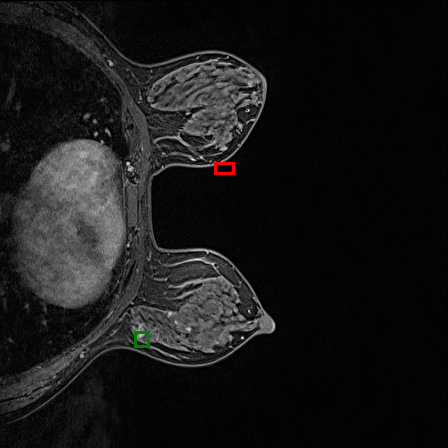

In [ ]:
print(len(data_processed["validation"]))
idx = np.random.randint(0,len(data_processed["validation"]))
val_pat = data_processed["validation"][idx]
image = val_pat["image"]
gt_json = val_pat["label"]

pred_raw_output = get_pred_raw_output(image)
print("Model raw output:", pred_raw_output)
print(gt_json)
overlaid = overlay_boxes(image, gt_json, pred_raw_output)
overlaid  # displays inline in Jupyter (green = ground truth, red = prediction)

In [ ]:
from typing import Any
import json

REPORT_PROMPT_1 = """
Instructions:

You are a breast MRI radiology assistant. Given a breast MRI image and available tumor localization information, generate a structured breast MRI report.

Follow this exact format:

Patient:
"""

REPORT_PROMPT_2 = """
------------------------------
Findings:
Fibroglandular Tissue:
Background Parenchymal Enhancement:

Left Breast:
Right Breast:
Axilla and Other:
"""

In [ ]:
#construct multi slide annotation

def MultislideApply(pat_row):
  #patient row
  image, mask = PreprocessNiiVol(
    Path(pat_row["Post Contrast 1"]),
    Path(pat_row["Annotation Box"]),
    slice=pat_row['Slide']
    )
  #print(mask)
  #check if gt report included
  # gt_report = 'No tumor in this breast'
  return {
      "pid": pat_row['Patient ID'],
      "image": image,
      "label": mask,
      "gt_report": pat_row["Ground Truth Report"]
  }

def MultislideAnnotationInference(patient, slide_count):
  pc1_slide_list = GetCenterSlides(nib.load(patient['Annotation Box']),slide_count+2)
  pc1_slide_list = pc1_slide_list[1:-1] # remove first and last

  #get pc1 corresponding list (delete after processing vols)

  #make multislide patient frame with z_slide attribute
  #make df with slide list # of patient repeated
  pc1_vol_path_list = []
  annotation_box_list = []
  pid_count_list = []
  gt_report_list = []
  z_slide_list = []
  for z in pc1_slide_list:
    pc1_vol_path_list.append(f"{patient['Post Contrast 1']}")
    annotation_box_list.append(f"{patient['Annotation Box']}")
    pid_count_list.append(patient['Patient ID'])
    gt_report_list.append(patient['Ground Truth Report'])
    z_slide_list.append(z)

  patient_pre_process_df = pd.DataFrame({
      'Patient ID': pid_count_list,
      'Post Contrast 1': pc1_vol_path_list,
      'Annotation Box': annotation_box_list,
      'Ground Truth Report': gt_report_list,
      'Slide': z_slide_list
  })

  #print(patient_pre_process_df)
  #convert to dictionary for specific patient?
  patient_data_dict = DatasetDict({
    "Val Patient": Dataset.from_pandas(patient_pre_process_df)
  })

  #print(patient_data_dict)

  #run mapping for dict
  pat_data_processed = patient_data_dict.map(
  MultislideApply,
  remove_columns=patient_data_dict['Val Patient'].column_names
  )

  return pat_data_processed




In [ ]:
map_val_dict = MultislideAnnotationInference(subset.iloc[0], 6)

Map:   0%|          | 0/4 [00:00<?, ? examples/s]

In [ ]:
def report_format_data(example: dict[str, Any]) -> dict[str, Any]:

    # GT report is the training target
    gt_report = example["gt_report"]

    #Get annotation boxes
    bbox_result= get_pred_raw_output(example['image'])
    #clean json
    try:
        bbox_json = json.loads(bbox_result)
        bbox_text = json.dumps(bbox_json)
    except:
        bbox_text = bbox_result

    report_prompt = REPORT_PROMPT_1 + example['pid'] + REPORT_PROMPT_2 + f""" Tumor localization predicted by detection model: {bbox_text}. You MUST only use this localization area of the image for information when generating the report. """

    example["messages"] = [
        {
            "role": "user",
            "content": [
                {
                    "type": "image",
                    "image": example["image"],
                },
                {
                    "type": "text",
                    "text": report_prompt,
                },
                {
                    "type": "text",
                    "text": bbox_text
                },
            ],
        },
        {
            "role": "assistant",
            "content": [
                {
                    "type": "text",
                    "text": gt_report,
                },
            ],
        },
    ]

    return example

In [ ]:
report_data_mapped = data_processed.map(report_format_data, remove_columns= ["label"],)


report_data_mapped["train"][0]

Map:   0%|          | 0/292 [00:00<?, ? examples/s]

Map:   0%|          | 0/73 [00:00<?, ? examples/s]

{'pid': 'Breast_MRI_331',
 'image': <PIL.PngImagePlugin.PngImageFile image mode=RGB size=512x512>,
 'gt_report': "Patient: Breast_MRI_331\n------------------------------\nFindings:\nFibroglandular Tissue: \\NA with \\NA% of breast FGT\nBackground Parenchymal Enhancement: \\NA\\ with \\NA%\\ of FGT tissue enhanced\n\nLeft Breast: \nTumor Location: \\L\\, \\ 1230 o'clock\\\nUnifocal/Multifocal: Tumor is \\Multifocal\\\nTumor Dimensions: Tumor is 1.418 cm x 1.740 cm x 1.540 cm\nTumor Volume: \\9.476\\ cm^3\nSkin Involvement: There is \\no skin involvement\\\nChest/Pec Involvement: There is \\no chest involvement\\\nRight Breast: Normal.\nAxilla and Other: There were \\no Lymphadenopathy\\Suspicious Nodes\\ found.",
 'messages': [{'content': [{'image': {'bytes': b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x02\x00\x00\x00\x02\x00\x08\x02\x00\x00\x00{\x1aC\xad\x00\x01\x00\x00IDATx\x9c\xec\xfdY\x93#W\x92\xe5\x89\xeb53\xc078|\x8b\x85deMVw\xf5<\x8c\xc8\xc8\x88t\x7f\xff\x0f0"\xd3O-\xd2\x0f=Y\x

In [ ]:
print(data_processed['train'][:5])

{'pid': ['Breast_MRI_331', 'Breast_MRI_173', 'Breast_MRI_034', 'Breast_MRI_048', 'Breast_MRI_370'], 'image': [<PIL.PngImagePlugin.PngImageFile image mode=RGB size=512x512 at 0x7DD721767820>, <PIL.PngImagePlugin.PngImageFile image mode=RGB size=512x512 at 0x7DD721767950>, <PIL.PngImagePlugin.PngImageFile image mode=RGB size=512x512 at 0x7DD721767A80>, <PIL.PngImagePlugin.PngImageFile image mode=RGB size=448x448 at 0x7DD721767BB0>, <PIL.PngImagePlugin.PngImageFile image mode=RGB size=448x448 at 0x7DD721767E10>], 'label': [[{'box_2d': [725, 645, 767, 697], 'label': 'Tumor'}], [{'box_2d': [226, 575, 282, 639], 'label': 'Tumor'}], [{'box_2d': [164, 617, 300, 895], 'label': 'Tumor'}], [{'box_2d': [630, 671, 678, 742], 'label': 'Tumor'}], [{'box_2d': [722, 678, 820, 843], 'label': 'Tumor'}]], 'gt_report': ["Patient: Breast_MRI_331\n------------------------------\nFindings:\nFibroglandular Tissue: \\NA with \\NA% of breast FGT\nBackground Parenchymal Enhancement: \\NA\\ with \\NA%\\ of FGT tis

In [ ]:
# import torch
from transformers import AutoProcessor, AutoModelForImageTextToText, BitsAndBytesConfig

# Check if GPU supports bfloat16
if torch.cuda.get_device_capability()[0] < 8:
    raise ValueError("GPU does not support bfloat16, please use a GPU that supports bfloat16.")

report_model_kwargs = dict(
    attn_implementation="eager",
    torch_dtype=torch.bfloat16,
    device_map="auto",
)

report_model_kwargs["quantization_config"] = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_use_double_quant=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=report_model_kwargs["torch_dtype"],
    bnb_4bit_quant_storage=report_model_kwargs["torch_dtype"],
)

report_model = AutoModelForImageTextToText.from_pretrained(model_id, **report_model_kwargs)
report_processor = AutoProcessor.from_pretrained(model_id)

# Use right padding to avoid issues during training
report_processor.tokenizer.padding_side = "right"

Loading weights:   0%|          | 0/883 [00:00<?, ?it/s]

In [ ]:
from peft import LoraConfig

report_peft_config = LoraConfig(
    lora_alpha=16,
    lora_dropout=0.05,
    r=16,
    bias="none",
    target_modules="all-linear",
    task_type="CAUSAL_LM",
    modules_to_save=[
        "lm_head",
        "embed_tokens",
    ],
)

In [ ]:
def collate_fn(examples):
    images = []
    texts = []

    for example in examples:
        images.append([example["image"].convert("RGB")])
        texts.append(
            report_processor.apply_chat_template(
                example["messages"],
                tokenize=False,
                add_generation_prompt=False,
            ).strip()
        )

    batch = report_processor(
        text=texts,
        images=images,
        return_tensors="pt",
        padding=True,
    )
    labels = batch["input_ids"].clone()
    labels[labels == report_processor.tokenizer.pad_token_id] = -100

    if hasattr(report_processor, "image_token_id"):
        labels[labels == report_processor.image_token_id] = -100

    batch["labels"] = labels

    return batch

In [ ]:
os.environ["WANDB_DISABLED"] = "true"
from trl import SFTConfig

num_train_epochs = 10
learning_rate = 2e-4

report_args = SFTConfig(
    output_dir="/content/drive/MyDrive/Duke_Dataset/BreastDCEDL_duke/BreastDCEDL_duke/models_medgemma",            # Directory and Hub repository id to save the model to
    num_train_epochs=num_train_epochs,                       # Number of training epochs
    per_device_train_batch_size=1,                           # Batch size per device during training
    per_device_eval_batch_size=1,                            # Batch size per device during evaluation
    gradient_accumulation_steps=8,                           # Number of steps before performing a backward/update pass
    gradient_checkpointing=True,                             # Enable gradient checkpointing to reduce memory usage
    optim="adamw_torch_fused",                               # Use fused AdamW optimizer for better performance
    logging_steps=50,                                        # Number of steps between logs
    save_strategy="epoch",                                   # Save checkpoint every epoch
    eval_strategy="steps",                                   # Evaluate every `eval_steps`
    eval_steps=50,                                           # Number of steps between evaluations
    learning_rate=learning_rate,                             # Learning rate based on QLoRA paper
    bf16=True,                                               # Use bfloat16 precision
    max_grad_norm=0.3,                                       # Max gradient norm based on QLoRA paper
    #warmup_ratio=0.03,                                       # Warmup ratio based on QLoRA paper
    lr_scheduler_type="linear",                              # Use linear learning rate scheduler
    push_to_hub=False,                                        # Push model to Hub
    report_to="none",                                 # Report metrics to tensorboard
    gradient_checkpointing_kwargs={"use_reentrant": False},  # Set gradient checkpointing to non-reentrant to avoid issues
    dataset_kwargs={"skip_prepare_dataset": True},           # Skip default dataset preparation to preprocess manually
    remove_unused_columns = False,                           # Columns are unused for training but needed for data collator
    label_names=["labels"],                                  # Input keys that correspond to the labels
)

In [ ]:
from trl import SFTTrainer

In [ ]:
import gc

gc.collect()
torch.cuda.empty_cache()
torch.cuda.ipc_collect()

In [ ]:
trainer = SFTTrainer(
    model=report_model,
    args=report_args,
    train_dataset=report_data_mapped["train"],
    eval_dataset=report_data_mapped["validation"].shuffle(),  # Use subset of validation set for faster run
    peft_config=report_peft_config,
    processing_class=report_processor,
    data_collator=collate_fn,
)

/usr/local/lib/python3.13/dist-packages/peft/tuners/tuners_utils.py:1463: UserWarning: Model has `tie_word_embeddings=True` and a tied layer is part of the adapter, but `ensure_weight_tying` is not set to True. This can lead to complications, for example when merging the adapter or converting your model to formats other than safetensors. Check the discussion here: https://github.com/huggingface/peft/issues/2777
  warnings.warn(msg)


In [ ]:
report_model.gradient_checkpointing_enable()
report_model.config.use_cache = False

trainer.train()

[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 1, 'bos_token_id': 2, 'pad_token_id': 0}.


Step,Training Loss,Validation Loss,Entropy,Num Tokens,Mean Token Accuracy
50,0.780193,0.108188,0.106597,248852.000000,0.959326
100,0.099619,0.102382,0.099059,497897.000000,0.961069
150,0.090287,0.102270,0.088845,744678.000000,0.961531
200,0.078959,0.109273,0.077549,993881.000000,0.962861
250,0.067196,0.118865,0.070783,1242839.000000,0.962519
300,0.052089,0.137437,0.060331,1489392.000000,0.962360
350,0.039264,0.149099,0.056147,1738613.000000,0.962419
370,0.039264,0.149271,0.056047,1836540.000000,0.962465


TrainOutput(global_step=370, training_loss=0.16507729001947352, metrics={'train_runtime': 7028.6595, 'train_samples_per_second': 0.415, 'train_steps_per_second': 0.053, 'total_flos': 4.775582883284928e+16, 'train_loss': 0.16507729001947352, 'epoch': 10.0})

In [ ]:
report_model.eval()

Gemma3ForConditionalGeneration(
  (model): Gemma3Model(
    (vision_tower): SiglipVisionModel(
      (embeddings): SiglipVisionEmbeddings(
        (patch_embedding): Conv2d(3, 1152, kernel_size=(14, 14), stride=(14, 14), padding=valid)
        (position_embedding): Embedding(4096, 1152)
      )
      (encoder): SiglipEncoder(
        (layers): ModuleList(
          (0-26): 27 x SiglipEncoderLayer(
            (layer_norm1): LayerNorm((1152,), eps=1e-06, elementwise_affine=True)
            (self_attn): SiglipAttention(
              (k_proj): lora.Linear4bit(
                (base_layer): Linear4bit(in_features=1152, out_features=1152, bias=True)
                (lora_dropout): ModuleDict(
                  (default): Dropout(p=0.05, inplace=False)
                )
                (lora_A): ModuleDict(
                  (default): Linear(in_features=1152, out_features=16, bias=False)
                )
                (lora_B): ModuleDict(
                  (default): Linear(in_feature

Example Reports


In [ ]:
train_reports = report_data_mapped["train"]["gt_report"]
val_reports = report_data_mapped["validation"]["gt_report"]


print("Number of train reports:", len(train_reports))
print("Number of val reports:", len(val_reports))

for i, report in enumerate(train_reports[:5]):
    print(i, repr(report[:50]))


train_pids = set()
val_pids = set()

for report in train_reports:
    match = re.search(r"Patient:\s*(Breast_MRI_\d+)", report)
    if match:
        train_pids.add(match.group(1))

for report in val_reports:
    match = re.search(r"Patient:\s*(Breast_MRI_\d+)", report)
    if match:
        val_pids.add(match.group(1))

print("Number train patients:", len(train_pids))
print("Number validation patients:", len(val_pids))

overlap = train_pids.intersection(val_pids)

print("Number overlapping:", len(overlap))
print("Overlapping patients:", sorted(overlap))

Number of train reports: 292
Number of val reports: 73
0 'Patient: Breast_MRI_331\n--------------------------'
1 'Patient: Breast_MRI_173\n--------------------------'
2 'Patient: Breast_MRI_034\n--------------------------'
3 'Patient: Breast_MRI_048\n--------------------------'
4 'Patient: Breast_MRI_370\n--------------------------'
Number train patients: 292
Number validation patients: 73
Number overlapping: 0
Overlapping patients: []


In [ ]:
def GenerateReport(index, slide_count):
  display_slides = slide_count

  #val_count = len(report_data_mapped["validation"])
  val_idx = index
  example = report_data_mapped["validation"][val_idx]

  #print(example)

  #get gt annotation
  cur_pid = example['gt_report'][9:23]
  #print(cur_pid)
  #grab the right df row from cur_pid to then find idx
  pat = subset[subset['Patient ID'] == cur_pid].iloc[0] # series
  #image , label = PreprocessNiiVol(pat['Post Contrast 1'], pat['Annotation Box'])

  #for inference grab more than 1 slide for prediction to display annotations
  multi_slide_processed_data = MultislideAnnotationInference(pat, display_slides+2)
  #print(multi_slide_processed_data)
  #no tumor on first couple of slides so select middle row
  mid_row = len(multi_slide_processed_data['Val Patient'])//2
  label = multi_slide_processed_data['Val Patient'][mid_row]['label']
  #print(f'GT {label}')
  messages = example["messages"]

  predicted_box = messages[0]["content"][2]
  #print(predicted_box.get("type"))
  box_json_str = predicted_box.get("text")
  #print(f"Predicted box {box_json_str}")


  # Same formatting as training
  text = report_processor.apply_chat_template(
      messages[:-1],
      tokenize=False,
      add_generation_prompt=True,
  ).strip()

  inputs = report_processor(
      text=[text],
      images=[[example["image"].convert("RGB")]],
      return_tensors="pt",
  )

  inputs = {k: v.to(report_model.device) for k, v in inputs.items()}

  with torch.no_grad():
      outputs = report_model.generate(
          **inputs,
          max_new_tokens=512,
          do_sample=False,
          temperature=None,
          top_p=None,
      )

  # Remove the prompt tokens
  generated_ids = outputs[:, inputs["input_ids"].shape[1]:]

  prediction = report_processor.batch_decode(
      generated_ids,
      skip_special_tokens=True,
  )[0]

  print("MEDGEMMA REPORT")
  print("-"*30)
  print(prediction)

  medgemma_report_str = f"MEDGEMMA REPORT: {prediction}"
  print("\n\nGROUND TRUTH")
  print("-"*30)
  print(example["messages"][1]["content"][0]["text"])
  gt_report_str = f"GROUND TRUTH: {example["messages"][1]["content"][0]["text"]}"


  #get annotation boxes:


  report_image = example["image"]
  #print(report_gt_json = example['label'])

  overlaid = overlay_boxes(report_image, label, box_json_str)
  #print(label)
  overlaid # display annotation box passed from first to second model

  overlay_plots = []
  for row in multi_slide_processed_data["Val Patient"]:
    pred_json_output = get_pred_raw_output(row['image'])
    overlay_plots.append(overlay_boxes(row['image'], row['label'], pred_json_output))

  #print(overlay_plots)

  fig, axes = plt.subplots(1, len(overlay_plots), figsize=(16, 4))

  for i, (ax, img) in enumerate(zip(axes, overlay_plots)):
      ax.imshow(img)
      ax.set_title(f"Slide {i+1}")
      ax.axis("off")

  plt.tight_layout()
  plt.show()
  return medgemma_report_str, gt_report_str, overlay_plots


73


Map:   0%|          | 0/7 [00:00<?, ? examples/s]

MEDGEMMA REPORT
------------------------------

Patient: Breast_MRI_065
------------------------------
Findings:
Fibroglandular Tissue: \NA with \NA% of breast FGT
Background Parenchymal Enhancement: \NA\ with \NA%\ of FGT tissue enhanced

Left Breast: 
Tumor Location: \L\, \ 12 o'clock\
Unifocal/Multifocal: Tumor is \Unifocal\
Tumor Dimensions: Tumor is 1.062 cm x 1.312 cm x 2.000 cm
Tumor Volume: \2.171\ cm^3
Skin Involvement: There is \no skin involvement\
Chest/Pec Involvement: There is \no chest involvement\
Right Breast: Normal.
Axilla and Other: There were \no Lymphadenopathy\Suspicious Nodes\ found.


GROUND TRUTH
------------------------------
Patient: Breast_MRI_065
------------------------------
Findings:
Fibroglandular Tissue: \NA with \NA% of breast FGT
Background Parenchymal Enhancement: \NA\ with \NA%\ of FGT tissue enhanced

Left Breast: 
Tumor Location: \L\, \ o'clock\
Unifocal/Multifocal: Tumor is \Unifocal\
Tumor Dimensions: Tumor is 4.148 cm x 3.516 cm x 8.600 cm
Tu

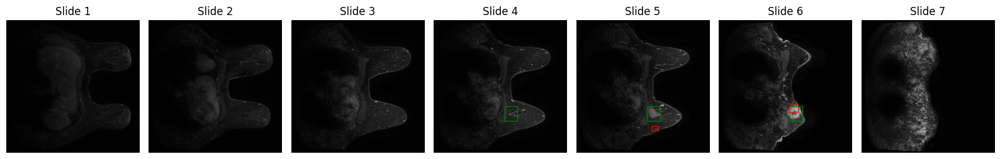

12 o'clock
o'clock
MEDGEMMA OCLCOK: 12.0
 GT OCLOCK 0

Fibroglandular Tissue: True

Patient: Breast_MRI_065
------------------------------
Findings:
Fibroglandular Tissue: True
Background Parenchymal Enhancement: True
Tumor Location (Right/Left Breast): True
Tumor Location (o'clock): False
Tumor Unifocal/Multifocal: True
Tumor Volume:
  MedGemma: 2.171 cm^3
  Ground Truth: 264.156 cm^3
Skin Involvement: True
Chest Involvement: True
Lymphadenopathy or Suspicious Nodes Found: True



Map:   0%|          | 0/6 [00:00<?, ? examples/s]

MEDGEMMA REPORT
------------------------------

Patient: Breast_MRI_243
------------------------------
Findings:
Fibroglandular Tissue: \NA with \NA% of breast FGT
Background Parenchymal Enhancement: \NA\ with \NA%\ of FGT tissue enhanced

Left Breast: Normal.
Right Breast: 
Tumor Location: \R\, \ 12 o'clock\
Unifocal/Multifocal: Tumor is \Unifocal\
Tumor Dimensions: Tumor is 1.436 cm x 1.250 cm x 1.320 cm
Tumor Volume: \5.052\ cm^3
Skin Involvement: There is \no skin involvement\
Chest/Pec Involvement: There is \no chest involvement\
Axilla and Other: There were \no Lymphadenopathy\Suspicious Nodes\ found.


GROUND TRUTH
------------------------------
Patient: Breast_MRI_243
------------------------------
Findings:
Fibroglandular Tissue: \NA with \NA% of breast FGT
Background Parenchymal Enhancement: \NA\ with \NA%\ of FGT tissue enhanced

Left Breast: 
Tumor Location: \L\, \ o'clock\
Unifocal/Multifocal: Tumor is \Unifocal\
Tumor Dimensions: Tumor is 1.504 cm x 2.119 cm x 2.860 cm
Tu

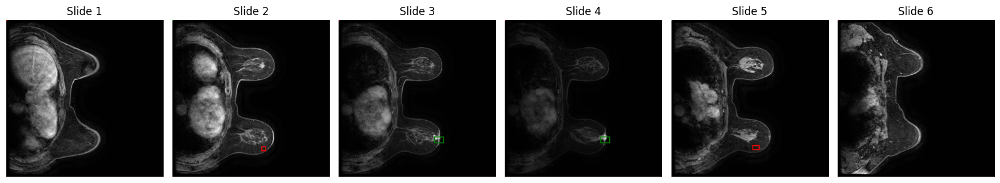

12 o'clock
o'clock
MEDGEMMA OCLCOK: 12.0
 GT OCLOCK 0

Fibroglandular Tissue: True

Patient: Breast_MRI_243
------------------------------
Findings:
Fibroglandular Tissue: True
Background Parenchymal Enhancement: True
Tumor Location (Right/Left Breast): False
Tumor Location (o'clock): False
Tumor Unifocal/Multifocal: True
Tumor Volume:
  MedGemma: 5.052 cm^3
  Ground Truth: 31.747 cm^3
Skin Involvement: False
Chest Involvement: True
Lymphadenopathy or Suspicious Nodes Found: True



Map:   0%|          | 0/7 [00:00<?, ? examples/s]

MEDGEMMA REPORT
------------------------------

Patient: Breast_MRI_292
------------------------------
Findings:
Fibroglandular Tissue: \NA with \NA% of breast FGT
Background Parenchymal Enhancement: \NA\ with \NA%\ of FGT tissue enhanced

Tumor location in breasts unmarked. Findings can not be attributed to specific breast:
Tumor Location: \nan\, \ 10 o'clock\
Unifocal/Multifocal: Tumor is \Unifocal\
Tumor Dimensions: Tumor is 2.700 cm x 3.527 cm x 4.200 cm
Tumor Volume: \26.619\ cm^3
Skin Involvement: There is \no skin involvement\
Chest/Pec Involvement: There is \no chest involvement\
Axilla and Other: There were \no Lymphadenopathy\Suspicious Nodes\ found.


GROUND TRUTH
------------------------------
Patient: Breast_MRI_292
------------------------------
Findings:
Fibroglandular Tissue: \NA with \NA% of breast FGT
Background Parenchymal Enhancement: \NA\ with \NA%\ of FGT tissue enhanced

Tumor location in breasts unmarked. Findings can not be attributed to specific breast:
Tumor 

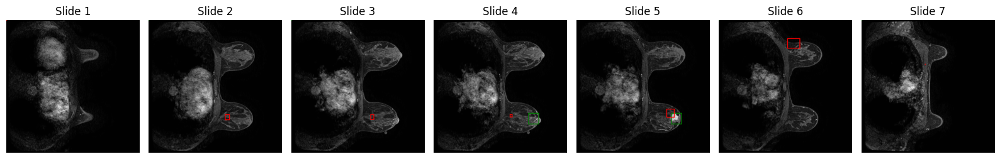

10 o'clock
12 o'clock
MEDGEMMA OCLCOK: 10.0
 GT OCLOCK 12.0

Fibroglandular Tissue: True

Patient: Breast_MRI_292
------------------------------
Findings:
Fibroglandular Tissue: True
Background Parenchymal Enhancement: True
Tumor Location (Right/Left Breast): True
Tumor Location (o'clock): False
Tumor Unifocal/Multifocal: False
Tumor Volume:
  MedGemma: 26.619 cm^3
  Ground Truth: 27.731 cm^3
Skin Involvement: True
Chest Involvement: True
Lymphadenopathy or Suspicious Nodes Found: True



Map:   0%|          | 0/7 [00:00<?, ? examples/s]

MEDGEMMA REPORT
------------------------------

Patient: Breast_MRI_051
------------------------------
Findings:
Fibroglandular Tissue: \NA with \NA% of breast FGT
Background Parenchymal Enhancement: \NA\ with \NA%\ of FGT tissue enhanced

Left Breast: 
Tumor Location: \L\, \ 12 o'clock\
Unifocal/Multifocal: Tumor is \Unifocal\
Tumor Dimensions: Tumor is 1.406 cm x 1.250 cm x 1.320 cm
Tumor Volume: \6.1 நினைவுகள்\ cm^3
Skin Involvement: There is \no skin involvement\
Chest/Pec Involvement: There is \no chest involvement\
Right Breast: Normal.
Axilla and Other: There were \no Lymphadenopathy\Suspicious Nodes\ found.


GROUND TRUTH
------------------------------
Patient: Breast_MRI_051
------------------------------
Findings:
Fibroglandular Tissue: \NA with \NA% of breast FGT
Background Parenchymal Enhancement: \NA\ with \NA%\ of FGT tissue enhanced

Left Breast: Normal.
Right Breast: 
Tumor Location: \R\, \ o'clock\
Unifocal/Multifocal: Tumor is \Unifocal\
Tumor Dimensions: Tumor is 1.1

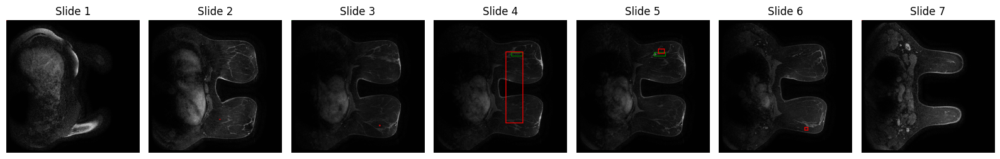

12 o'clock
o'clock
MEDGEMMA OCLCOK: 12.0
 GT OCLOCK 0

Fibroglandular Tissue: True

Patient: Breast_MRI_051
------------------------------
Findings:
Fibroglandular Tissue: True
Background Parenchymal Enhancement: True
Tumor Location (Right/Left Breast): False
Tumor Location (o'clock): False
Tumor Unifocal/Multifocal: True
Tumor Volume:
  MedGemma: 6.1 நினைவுகள் cm^3
  Ground Truth: 3.773 cm^3
Skin Involvement: True
Chest Involvement: True
Lymphadenopathy or Suspicious Nodes Found: False



Map:   0%|          | 0/7 [00:00<?, ? examples/s]

MEDGEMMA REPORT
------------------------------

Patient: Breast_MRI_216
------------------------------
Findings:
Fibroglandular Tissue: \NA with \NA% of breast FGT
Background Parenchymal Enhancement: \NA\ with \NA%\ of FGT tissue enhanced

Tumor location in breasts unmarked. Findings can not be attributed to specific breast:
Tumor Location: \nan\, \ 10, R 8 o'clock\
Unifocal/Multifocal: Tumor is \Multifocal\
Tumor Dimensions: Tumor is 4.170 cm x 4.170 cm x 4.170 cm
Tumor Volume: \17.035\ cm^3
Skin Involvement: There is \no skin involvement\
Chest/Pec Involvement: There is \no chest involvement\
Axilla and Other: There were \no Lymphadenopathy\Suspicious Nodes\ found.


GROUND TRUTH
------------------------------
Patient: Breast_MRI_216
------------------------------
Findings:
Fibroglandular Tissue: \NA with \NA% of breast FGT
Background Parenchymal Enhancement: \NA\ with \NA%\ of FGT tissue enhanced

Tumor location in breasts unmarked. Findings can not be attributed to specific breast:

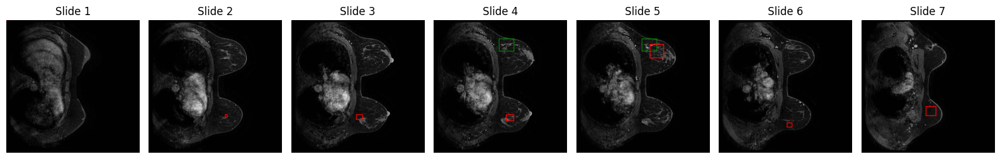

10, R 8 o'clock
o'clock
MEDGEMMA OCLCOK: 10.0
 GT OCLOCK 0

Fibroglandular Tissue: True

Patient: Breast_MRI_216
------------------------------
Findings:
Fibroglandular Tissue: True
Background Parenchymal Enhancement: True
Tumor Location (Right/Left Breast): True
Tumor Location (o'clock): False
Tumor Unifocal/Multifocal: False
Tumor Volume:
  MedGemma: 17.035 cm^3
  Ground Truth: 28.520 cm^3
Skin Involvement: True
Chest Involvement: True
Lymphadenopathy or Suspicious Nodes Found: True



Map:   0%|          | 0/7 [00:00<?, ? examples/s]

MEDGEMMA REPORT
------------------------------

Patient: Breast_MRI_348
------------------------------
Findings:
Fibroglandular Tissue: \NA with \NA% of breast FGT
Background Parenchymal Enhancement: \NA\ with \NA%\ of FGT tissue enhanced

Left Breast: 
Tumor Location: \L\, \ 1 o'clock\
Unifocal/Multifocal: Tumor is \Unifocal\
Tumor Dimensions: Tumor is 2.258 cm x 2.922 cm x 3.400 cm
Tumor Volume: \27.647\ cm^3
Skin Involvement: There is \no skin involvement\
Chest/Pec Involvement: There is \no chest involvement\
Right Breast: Normal.
Axilla and Other: There were \no Lymphadenopathy\Suspicious Nodes\ found.


GROUND TRUTH
------------------------------
Patient: Breast_MRI_348
------------------------------
Findings:
Fibroglandular Tissue: \NA with \NA% of breast FGT
Background Parenchymal Enhancement: \NA\ with \NA%\ of FGT tissue enhanced

Tumor is BILATERAL. Findings span both breasts:
Tumor Location: \Bilateral\, \, R o'clock\
Unifocal/Multifocal: Tumor is \Multifocal\
Tumor Dimensi

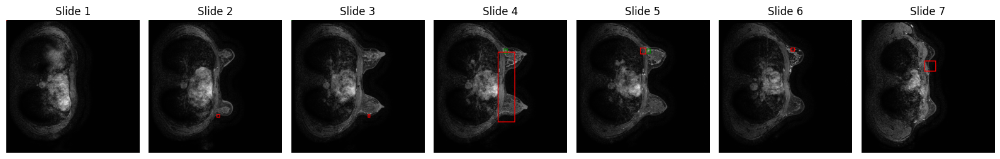

1 o'clock
 R o'clock
MEDGEMMA OCLCOK: 1.0
 GT OCLOCK 0

Fibroglandular Tissue: True

Patient: Breast_MRI_348
------------------------------
Findings:
Fibroglandular Tissue: True
Background Parenchymal Enhancement: True
Tumor Location (Right/Left Breast): False
Tumor Location (o'clock): False
Tumor Unifocal/Multifocal: False
Tumor Volume:
  MedGemma: 27.647 cm^3
  Ground Truth: 8.847 cm^3
Skin Involvement: True
Chest Involvement: True
Lymphadenopathy or Suspicious Nodes Found: False



Map:   0%|          | 0/6 [00:00<?, ? examples/s]

MEDGEMMA REPORT
------------------------------

Patient: Breast_MRI_269
------------------------------
Findings:
Fibroglandular Tissue: \NA with \NA% of breast FGT
Background Parenchymal Enhancement: \NA\ with \NA%\ of FGT tissue enhanced

Tumor location in breasts unmarked. Findings can not be attributed to specific breast:
Tumor Location: \nan\, \ 8 o'clock\
Unifocal/Multifocal: Tumor is \Unifocal\
Tumor Dimensions: Tumor is 2.719 cm x 3.623 cm x 4.000 cm
Tumor Volume: \41.931\ cm^3
Skin Involvement: There is \no skin involvement\
Chest/Pec Involvement: There is \no chest involvement\
Axilla and Other: There were \no Lymphadenopathy\Suspicious Nodes\ found.


GROUND TRUTH
------------------------------
Patient: Breast_MRI_269
------------------------------
Findings:
Fibroglandular Tissue: \NA with \NA% of breast FGT
Background Parenchymal Enhancement: \NA\ with \NA%\ of FGT tissue enhanced

Tumor location in breasts unmarked. Findings can not be attributed to specific breast:
Tumor L

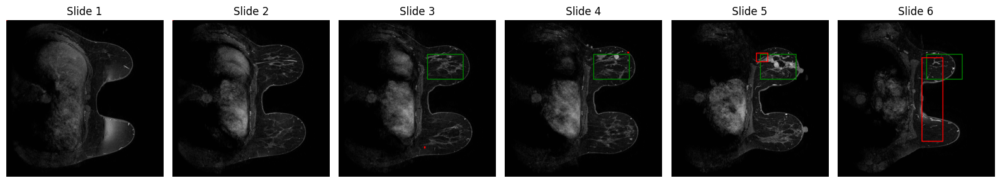

8 o'clock
9, R 12 o'clock
MEDGEMMA OCLCOK: 8.0
 GT OCLOCK 0

Fibroglandular Tissue: True

Patient: Breast_MRI_269
------------------------------
Findings:
Fibroglandular Tissue: True
Background Parenchymal Enhancement: True
Tumor Location (Right/Left Breast): True
Tumor Location (o'clock): False
Tumor Unifocal/Multifocal: False
Tumor Volume:
  MedGemma: 41.931 cm^3
  Ground Truth: 391.194 cm^3
Skin Involvement: True
Chest Involvement: True
Lymphadenopathy or Suspicious Nodes Found: False



Map:   0%|          | 0/6 [00:00<?, ? examples/s]

MEDGEMMA REPORT
------------------------------

Patient: Breast_MRI_194
------------------------------
Findings:
Fibroglandular Tissue: \NA with \NA% of breast FGT
Background Parenchymal Enhancement: \NA\ with \NA%\ of FGT tissue enhanced

Left Breast: Normal.
Right Breast: 
Tumor Location: \R\, \ 10 o'clock\
Unifocal/Multifocal: Tumor is \Unifocal\
Tumor Dimensions: Tumor is 2.059 cm x 2.457 cm x 4.800 cm
Tumor Volume: \43.713\ cm^3
Skin Involvement: There is \no skin involvement\
Chest/Pec Involvement: There is \no chest involvement\
Axilla and Other: There were \no Lymphadenopathy\Suspicious Nodes\ found.


GROUND TRUTH
------------------------------
Patient: Breast_MRI_194
------------------------------
Findings:
Fibroglandular Tissue: \NA with \NA% of breast FGT
Background Parenchymal Enhancement: \NA\ with \NA%\ of FGT tissue enhanced

Left Breast: Normal.
Right Breast: 
Tumor Location: \R\, \ 9 o'clock\
Unifocal/Multifocal: Tumor is \Unifocal\
Tumor Dimensions: Tumor is 1.332 cm

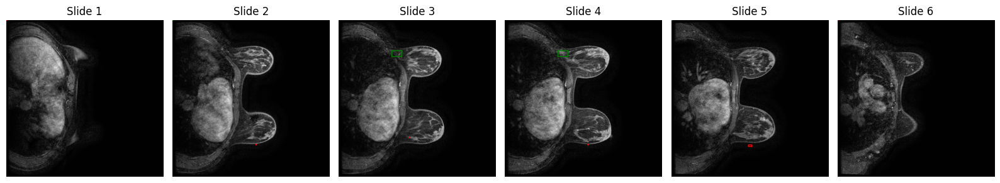

10 o'clock
9 o'clock
MEDGEMMA OCLCOK: 10.0
 GT OCLOCK 9.0

Fibroglandular Tissue: True

Patient: Breast_MRI_194
------------------------------
Findings:
Fibroglandular Tissue: True
Background Parenchymal Enhancement: True
Tumor Location (Right/Left Breast): True
Tumor Location (o'clock): False
Tumor Unifocal/Multifocal: True
Tumor Volume:
  MedGemma: 43.713 cm^3
  Ground Truth: 32.723 cm^3
Skin Involvement: True
Chest Involvement: True
Lymphadenopathy or Suspicious Nodes Found: True



Map:   0%|          | 0/7 [00:00<?, ? examples/s]

MEDGEMMA REPORT
------------------------------

Patient: Breast_MRI_295
------------------------------
Findings:
Fibroglandular Tissue: \NA with \NA% of breast FGT
Background Parenchymal Enhancement: \NA\ with \NA%\ of FGT tissue enhanced

Left Breast: 
Tumor Location: \L\, \ 1 o'clock\
Unifocal/Multifocal: Tumor is \Unifocal\
Tumor Dimensions: Tumor is 2.059 cm x 2.457 cm x 3.600 cm
Tumor Volume: \33.682\ cm^3
Skin Involvement: There is \no skin involvement\
Chest/Pec Involvement: There is \no chest involvement\
Right Breast: Normal.
Axilla and Other: There were \no Lymphadenopathy\Suspicious Nodes\ found.


GROUND TRUTH
------------------------------
Patient: Breast_MRI_295
------------------------------
Findings:
Fibroglandular Tissue: \NA with \NA% of breast FGT
Background Parenchymal Enhancement: \NA\ with \NA%\ of FGT tissue enhanced

Left Breast: Normal.
Right Breast: 
Tumor Location: \R\, \ 1 o'clock\
Unifocal/Multifocal: Tumor is \Unifocal\
Tumor Dimensions: Tumor is 1.477 cm 

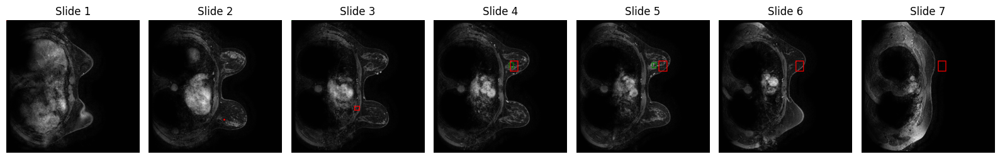

1 o'clock
1 o'clock
MEDGEMMA OCLCOK: 1.0
 GT OCLOCK 1.0

Fibroglandular Tissue: True

Patient: Breast_MRI_295
------------------------------
Findings:
Fibroglandular Tissue: True
Background Parenchymal Enhancement: True
Tumor Location (Right/Left Breast): False
Tumor Location (o'clock): True
Tumor Unifocal/Multifocal: True
Tumor Volume:
  MedGemma: 33.682 cm^3
  Ground Truth: 5.764 cm^3
Skin Involvement: True
Chest Involvement: True
Lymphadenopathy or Suspicious Nodes Found: True



Map:   0%|          | 0/6 [00:00<?, ? examples/s]

MEDGEMMA REPORT
------------------------------

Patient: Breast_MRI_260
------------------------------
Findings:
Fibroglandular Tissue: \NA with \NA% of breast FGT
Background Parenchymal Enhancement: \NA\ with \NA%\ of FGT tissue enhanced

Tumor location in breasts unmarked. Findings can not be attributed to specific breast:
Tumor Location: \nan\, \ 12 o'clock\
Unifocal/Multifocal: Tumor is \Unifocal\
Tumor Dimensions: Tumor is 2.062 cm x 1.656 cm x 1.800 cm
Tumor Volume: \20.044\ cm^3
Skin Involvement: There is \no skin involvement\
Chest/Pec Involvement: There is \no chest involvement\
Axilla and Other: There were \no Lymphadenopathy\Suspicious Nodes\ found.


GROUND TRUTH
------------------------------
Patient: Breast_MRI_260
------------------------------
Findings:
Fibroglandular Tissue: \NA with \NA% of breast FGT
Background Parenchymal Enhancement: \NA\ with \NA%\ of FGT tissue enhanced

Left Breast: Normal.
Right Breast: 
Tumor Location: \R\, \ 3, R 8 o'clock\
Unifocal/Multifoca

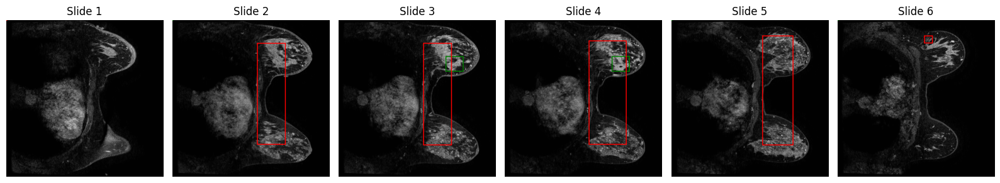

12 o'clock
3, R 8 o'clock
MEDGEMMA OCLCOK: 12.0
 GT OCLOCK 0

Fibroglandular Tissue: True

Patient: Breast_MRI_260
------------------------------
Findings:
Fibroglandular Tissue: True
Background Parenchymal Enhancement: True
Tumor Location (Right/Left Breast): False
Tumor Location (o'clock): False
Tumor Unifocal/Multifocal: False
Tumor Volume:
  MedGemma: 20.044 cm^3
  Ground Truth: 68.524 cm^3
Skin Involvement: True
Chest Involvement: True
Lymphadenopathy or Suspicious Nodes Found: False



Map:   0%|          | 0/7 [00:00<?, ? examples/s]

MEDGEMMA REPORT
------------------------------

Patient: Breast_MRI_166
------------------------------
Findings:
Fibroglandular Tissue: \NA with \NA% of breast FGT
Background Parenchymal Enhancement: \NA\ with \NA%\ of FGT tissue enhanced

Left Breast: Normal.
Right Breast: 
Tumor Location: \R\, \ 12 o'clock\
Unifocal/Multifocal: Tumor is \Unifocal\
Tumor Dimensions: Tumor is 1.275 cm x 1.211 cm x 1.800 cm
Tumor Volume: \5.994\ cm^3
Skin Involvement: There is \no skin involvement\
Chest/Pec Involvement: There is \no chest involvement\
Axilla and Other: There were \no Lymphadenopathy\Suspicious Nodes\ found.


GROUND TRUTH
------------------------------
Patient: Breast_MRI_166
------------------------------
Findings:
Fibroglandular Tissue: \NA with \NA% of breast FGT
Background Parenchymal Enhancement: \NA\ with \NA%\ of FGT tissue enhanced

Tumor location in breasts unmarked. Findings can not be attributed to specific breast:
Tumor Location: \nan\, \ o'clock\
Unifocal/Multifocal: Tumor

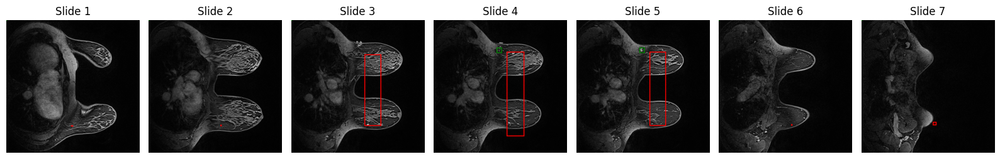

12 o'clock
o'clock
MEDGEMMA OCLCOK: 12.0
 GT OCLOCK 0

Fibroglandular Tissue: True

Patient: Breast_MRI_166
------------------------------
Findings:
Fibroglandular Tissue: True
Background Parenchymal Enhancement: True
Tumor Location (Right/Left Breast): False
Tumor Location (o'clock): False
Tumor Unifocal/Multifocal: True
Tumor Volume:
  MedGemma: 5.994 cm^3
  Ground Truth: 3.257 cm^3
Skin Involvement: True
Chest Involvement: True
Lymphadenopathy or Suspicious Nodes Found: True



Map:   0%|          | 0/7 [00:00<?, ? examples/s]

MEDGEMMA REPORT
------------------------------

Patient: Breast_MRI_156
------------------------------
Findings:
Fibroglandular Tissue: \NA with \NA% of breast FGT
Background Parenchymal Enhancement: \NA\ with \NA%\ of FGT tissue enhanced

Left Breast: 
Tumor Location: \L\, \ 1 o'clock\
Unifocal/Multifocal: Tumor is \Unifocal\
Tumor Dimensions: Tumor is 2.059 cm x 2.254 cm x 3.200 cm
Tumor Volume: \23.494\ cm^3
Skin Involvement: There is \no skin involvement\
Chest/Pec Involvement: There is \no chest involvement\
Right Breast: Normal.
Axilla and Other: There were \no Lymphadenopathy\Suspicious Nodes\ found.


GROUND TRUTH
------------------------------
Patient: Breast_MRI_156
------------------------------
Findings:
Fibroglandular Tissue: \NA with \NA% of breast FGT
Background Parenchymal Enhancement: \NA\ with \NA%\ of FGT tissue enhanced

Left Breast: Normal.
Right Breast: 
Tumor Location: \R\, \ 10, R 11, R 12 o'clock\
Unifocal/Multifocal: Tumor is \Unifocal\
Tumor Dimensions: Tumor

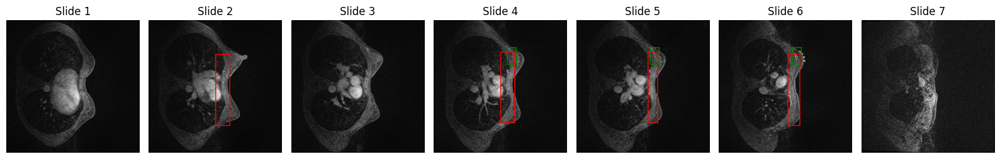

1 o'clock
10, R 11, R 12 o'clock
MEDGEMMA OCLCOK: 1.0
 GT OCLOCK 10.0

Fibroglandular Tissue: True

Patient: Breast_MRI_156
------------------------------
Findings:
Fibroglandular Tissue: True
Background Parenchymal Enhancement: True
Tumor Location (Right/Left Breast): False
Tumor Location (o'clock): False
Tumor Unifocal/Multifocal: True
Tumor Volume:
  MedGemma: 23.494 cm^3
  Ground Truth: 110.616 cm^3
Skin Involvement: True
Chest Involvement: True
Lymphadenopathy or Suspicious Nodes Found: True

Repicking New Sample Vol


Map:   0%|          | 0/6 [00:00<?, ? examples/s]

MEDGEMMA REPORT
------------------------------

Patient: Breast_MRI_150
------------------------------
Findings:
Fibroglandular Tissue: \NA with \NA% of breast FGT
Background Parenchymal Enhancement: \NA\ with \NA%\ of FGT tissue enhanced

Tumor location in breasts unmarked. Findings can not be attributed to specific breast:
Tumor Location: \nan\, \ 12 o'clock\
Unifocal/Multifocal: Tumor is \Unifocal\
Tumor Dimensions: Tumor is 2.258 cm x 2.922 cm x 3.400 cm
Tumor Volume: \23.310\ cm^3
Skin Involvement: There is \no skin involvement\
Chest/Pec Involvement: There is \no chest involvement\
Axilla and Other: There were \no Lymphadenopathy\Suspicious Nodes\ found.


GROUND TRUTH
------------------------------
Patient: Breast_MRI_150
------------------------------
Findings:
Fibroglandular Tissue: \NA with \NA% of breast FGT
Background Parenchymal Enhancement: \NA\ with \NA%\ of FGT tissue enhanced

Tumor location in breasts unmarked. Findings can not be attributed to specific breast:
Tumor 

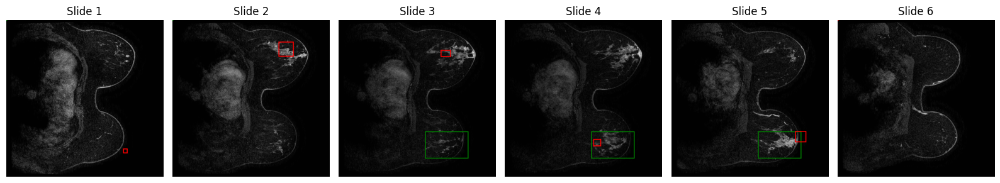

12 o'clock
2, L 6 o'clock
MEDGEMMA OCLCOK: 12.0
 GT OCLOCK 0

Fibroglandular Tissue: True

Patient: Breast_MRI_150
------------------------------
Findings:
Fibroglandular Tissue: True
Background Parenchymal Enhancement: True
Tumor Location (Right/Left Breast): True
Tumor Location (o'clock): False
Tumor Unifocal/Multifocal: False
Tumor Volume:
  MedGemma: 23.310 cm^3
  Ground Truth: 246.132 cm^3
Skin Involvement: True
Chest Involvement: True
Lymphadenopathy or Suspicious Nodes Found: True



Map:   0%|          | 0/7 [00:00<?, ? examples/s]

MEDGEMMA REPORT
------------------------------

Patient: Breast_MRI_009
------------------------------
Findings:
Fibroglandular Tissue: \NA with \NA% of breast FGT
Background Parenchymal Enhancement: \NA\ with \NA%\ of FGT tissue enhanced

Left Breast: Normal.
Right Breast: 
Tumor Location: \R\, \ 10 o'clock\
Unifocal/Multifocal: Tumor is \Unifocal\
Tumor Dimensions: Tumor is 0.875 cm x 1.250 cm x 0.810 cm
Tumor Volume: \1.662\ cm^3
Skin Involvement: There is \no skin involvement\
Chest/Pec Involvement: There is \no chest involvement\
Axilla and Other: There were \no Lymphadenopathy\Suspicious Nodes\ found.


GROUND TRUTH
------------------------------
Patient: Breast_MRI_009
------------------------------
Findings:
Fibroglandular Tissue: \NA with \NA% of breast FGT
Background Parenchymal Enhancement: \NA\ with \NA%\ of FGT tissue enhanced

Left Breast: Normal.
Right Breast: 
Tumor Location: \R\, \ 10 o'clock\
Unifocal/Multifocal: Tumor is \Multifocal\
Tumor Dimensions: Tumor is 2.922 

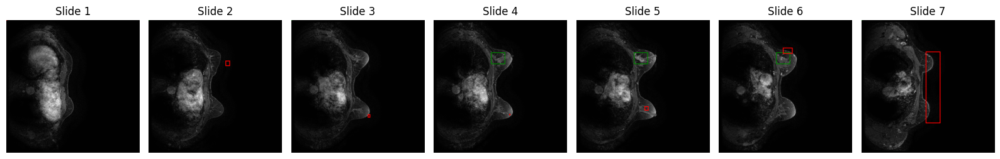

10 o'clock
10 o'clock
MEDGEMMA OCLCOK: 10.0
 GT OCLOCK 10.0

Fibroglandular Tissue: True

Patient: Breast_MRI_009
------------------------------
Findings:
Fibroglandular Tissue: True
Background Parenchymal Enhancement: True
Tumor Location (Right/Left Breast): True
Tumor Location (o'clock): True
Tumor Unifocal/Multifocal: False
Tumor Volume:
  MedGemma: 1.662 cm^3
  Ground Truth: 52.399 cm^3
Skin Involvement: True
Chest Involvement: True
Lymphadenopathy or Suspicious Nodes Found: True

Repicking New Sample Vol


Map:   0%|          | 0/7 [00:00<?, ? examples/s]

MEDGEMMA REPORT
------------------------------

Patient: Breast_MRI_054
------------------------------
Findings:
Fibroglandular Tissue: \NA with \NA% of breast FGT
Background Parenchymal Enhancement: \NA\ with \NA%\ of FGT tissue enhanced

Left Breast: Normal.
Right Breast: 
Tumor Location: \R\, \ 12 o'clock\
Unifocal/Multifocal: Tumor is \Unifocal\
Tumor Dimensions: Tumor is 1.938 cm x 1.688 cm x 1.210 cm
Tumor Volume: \11.882\ cm^3
Skin Involvement: There is \no skin involvement\
Chest/Pec Involvement: There is \no chest involvement\
Axilla and Other: There were \no Lymphadenopathy\Suspicious Nodes\ found.


GROUND TRUTH
------------------------------
Patient: Breast_MRI_054
------------------------------
Findings:
Fibroglandular Tissue: \NA with \NA% of breast FGT
Background Parenchymal Enhancement: \NA\ with \NA%\ of FGT tissue enhanced

Tumor location in breasts unmarked. Findings can not be attributed to specific breast:
Tumor Location: \nan\, \ 12 o'clock\
Unifocal/Multifocal: T

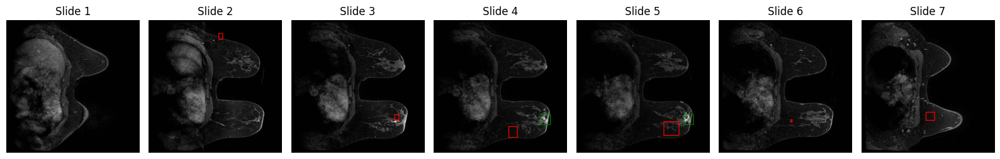

12 o'clock
12 o'clock
MEDGEMMA OCLCOK: 12.0
 GT OCLOCK 12.0

Fibroglandular Tissue: True

Patient: Breast_MRI_054
------------------------------
Findings:
Fibroglandular Tissue: True
Background Parenchymal Enhancement: True
Tumor Location (Right/Left Breast): False
Tumor Location (o'clock): True
Tumor Unifocal/Multifocal: True
Tumor Volume:
  MedGemma: 11.882 cm^3
  Ground Truth: 42.371 cm^3
Skin Involvement: True
Chest Involvement: True
Lymphadenopathy or Suspicious Nodes Found: True



Map:   0%|          | 0/7 [00:00<?, ? examples/s]

MEDGEMMA REPORT
------------------------------

Patient: Breast_MRI_237
------------------------------
Findings:
Fibroglandular Tissue: \NA with \NA% of breast FGT
Background Parenchymal Enhancement: \NA\ with \NA%\ of FGT tissue enhanced

Left Breast: 
Tumor Location: \L\, \ 1 o'clock\
Unifocal/Multifocal: Tumor is \Unifocal\
Tumor Dimensions: Tumor is 2.461 cm x 2.188 cm x 3.900 cm
Tumor Volume: \33.690\ cm^3
Skin Involvement: There is \no skin involvement\
Chest/Pec Involvement: There is \no chest involvement\
Right Breast: Normal.
Axilla and Other: There were \no Lymphadenopathy\Suspicious Nodes\ found.


GROUND TRUTH
------------------------------
Patient: Breast_MRI_237
------------------------------
Findings:
Fibroglandular Tissue: \NA with \NA% of breast FGT
Background Parenchymal Enhancement: \NA\ with \NA%\ of FGT tissue enhanced

Left Breast: 
Tumor Location: \L\, \ 2-3 o'clock\
Unifocal/Multifocal: Tumor is \Unifocal\
Tumor Dimensions: Tumor is 4.050 cm x 3.825 cm x 3.520 c

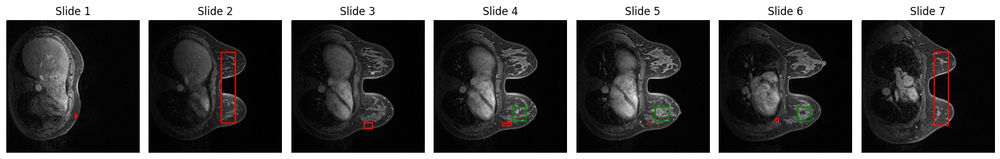

1 o'clock
2-3 o'clock
MEDGEMMA OCLCOK: 1.0
 GT OCLOCK 0

Fibroglandular Tissue: True

Patient: Breast_MRI_237
------------------------------
Findings:
Fibroglandular Tissue: True
Background Parenchymal Enhancement: True
Tumor Location (Right/Left Breast): True
Tumor Location (o'clock): False
Tumor Unifocal/Multifocal: True
Tumor Volume:
  MedGemma: 33.690 cm^3
  Ground Truth: 187.834 cm^3
Skin Involvement: True
Chest Involvement: True
Lymphadenopathy or Suspicious Nodes Found: False

Repicking New Sample Vol


Map:   0%|          | 0/6 [00:00<?, ? examples/s]

MEDGEMMA REPORT
------------------------------

Patient: Breast_MRI_149
------------------------------
Findings:
Fibroglandular Tissue: \NA with \NA% of breast FGT
Background Parenchymal Enhancement: \NA\ with \NA%\ of FGT tissue enhanced

Left Breast: 
Tumor Location: \L\, \ 1 o'clock\
Unifocal/Multifocal: Tumor is \Unifocal\
Tumor Dimensions: Tumor is 2.059 cm x 2.457 cm x 3.600 cm
Tumor Volume: \33.682\ cm^3
Skin Involvement: There is \no skin involvement\
Chest/Pec Involvement: There is \no chest involvement\
Right Breast: Normal.
Axilla and Other: There were \no Lymphadenopathy\Suspicious Nodes\ found.


GROUND TRUTH
------------------------------
Patient: Breast_MRI_149
------------------------------
Findings:
Fibroglandular Tissue: \NA with \NA% of breast FGT
Background Parenchymal Enhancement: \NA\ with \NA%\ of FGT tissue enhanced

Tumor location in breasts unmarked. Findings can not be attributed to specific breast:
Tumor Location: \nan\, \ o'clock\
Unifocal/Multifocal: Tumor

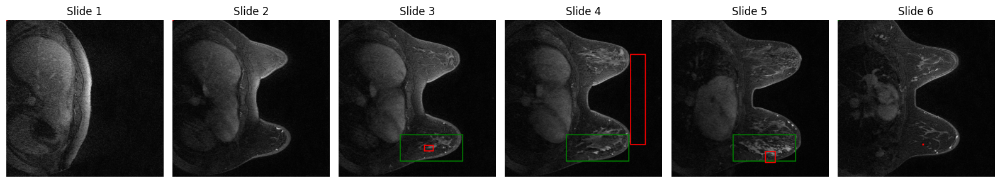

1 o'clock
o'clock
MEDGEMMA OCLCOK: 1.0
 GT OCLOCK 0

Fibroglandular Tissue: True

Patient: Breast_MRI_149
------------------------------
Findings:
Fibroglandular Tissue: True
Background Parenchymal Enhancement: True
Tumor Location (Right/Left Breast): False
Tumor Location (o'clock): False
Tumor Unifocal/Multifocal: True
Tumor Volume:
  MedGemma: 33.682 cm^3
  Ground Truth: 311.222 cm^3
Skin Involvement: True
Chest Involvement: True
Lymphadenopathy or Suspicious Nodes Found: False



Map:   0%|          | 0/6 [00:00<?, ? examples/s]

MEDGEMMA REPORT
------------------------------

Patient: Breast_MRI_003
------------------------------
Findings:
Fibroglandular Tissue: \NA with \NA% of breast FGT
Background Parenchymal Enhancement: \NA\ with \NA%\ of FGT tissue enhanced

Left Breast: 
Tumor Location: \L\, \ 12 o'clock\
Unifocal/Multifocal: Tumor is \Unifocal\
Tumor Dimensions: Tumor is 2.524 cm x 2.656 cm x 3.400 cm
Tumor Volume: \38.461\ cm^3
Skin Involvement: There is \no skin involvement\
Chest/Pec Involvement: There is \no chest involvement\
Right Breast: Normal.
Axilla and Other: There were \no Lymphadenopathy\Suspicious Nodes\ found.


GROUND TRUTH
------------------------------
Patient: Breast_MRI_003
------------------------------
Findings:
Fibroglandular Tissue: \NA with \NA% of breast FGT
Background Parenchymal Enhancement: \NA\ with \NA%\ of FGT tissue enhanced

Tumor location in breasts unmarked. Findings can not be attributed to specific breast:
Tumor Location: \nan\, \ 2 o'clock\
Unifocal/Multifocal: Tu

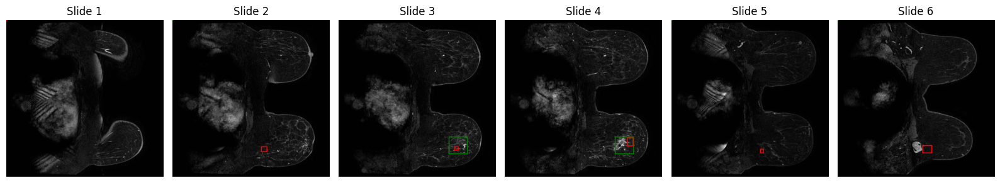

12 o'clock
2 o'clock
MEDGEMMA OCLCOK: 12.0
 GT OCLOCK 2.0

Fibroglandular Tissue: True

Patient: Breast_MRI_003
------------------------------
Findings:
Fibroglandular Tissue: True
Background Parenchymal Enhancement: True
Tumor Location (Right/Left Breast): False
Tumor Location (o'clock): False
Tumor Unifocal/Multifocal: False
Tumor Volume:
  MedGemma: 38.461 cm^3
  Ground Truth: 24.426 cm^3
Skin Involvement: True
Chest Involvement: True
Lymphadenopathy or Suspicious Nodes Found: False



Map:   0%|          | 0/7 [00:00<?, ? examples/s]

MEDGEMMA REPORT
------------------------------

Patient: Breast_MRI_158
------------------------------
Findings:
Fibroglandular Tissue: \NA with \NA% of breast FGT
Background Parenchymal Enhancement: \NA\ with \NA%\ of FGT tissue enhanced

Left Breast: 
Tumor Location: \L\, \ 1 o'clock\
Unifocal/Multifocal: Tumor is \Unifocal\
Tumor Dimensions: Tumor is 1.406 cm x 1.250 cm x 1.320 cm
Tumor Volume: \5.024\ cm^3
Skin Involvement: There is \no skin involvement\
Chest/Pec Involvement: There is \no chest involvement\
Right Breast: Normal.
Axilla and Other: There were \no Lymphadenopathy\Suspicious Nodes\ found.


GROUND TRUTH
------------------------------
Patient: Breast_MRI_158
------------------------------
Findings:
Fibroglandular Tissue: \NA with \NA% of breast FGT
Background Parenchymal Enhancement: \NA\ with \NA%\ of FGT tissue enhanced

Left Breast: 
Tumor Location: \L\, \ o'clock\
Unifocal/Multifocal: Tumor is \Unifocal\
Tumor Dimensions: Tumor is 4.460 cm x 7.433 cm x 8.000 cm
Tum

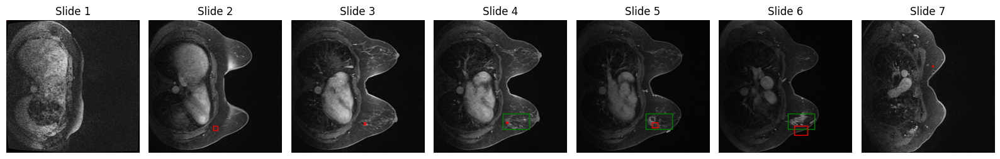

1 o'clock
o'clock
MEDGEMMA OCLCOK: 1.0
 GT OCLOCK 0

Fibroglandular Tissue: True

Patient: Breast_MRI_158
------------------------------
Findings:
Fibroglandular Tissue: True
Background Parenchymal Enhancement: True
Tumor Location (Right/Left Breast): True
Tumor Location (o'clock): False
Tumor Unifocal/Multifocal: True
Tumor Volume:
  MedGemma: 5.024 cm^3
  Ground Truth: 179.174 cm^3
Skin Involvement: True
Chest Involvement: True
Lymphadenopathy or Suspicious Nodes Found: False

Repicking New Sample Vol
Repicking New Sample Vol


Map:   0%|          | 0/6 [00:00<?, ? examples/s]

MEDGEMMA REPORT
------------------------------

Patient: Breast_MRI_213
------------------------------
Findings:
Fibroglandular Tissue: \NA with \NA% of breast FGT
Background Parenchymal Enhancement: \NA\ with \NA%\ of FGT tissue enhanced

Left Breast: 
Tumor Location: \L\, \ 1 o'clock\
Unifocal/Multifocal: Tumor is \Unifocal\
Tumor Dimensions: Tumor is 1.438 cm x 1.250 cm x 1.800 cm
Tumor Volume: \5.002\ cm^3
Skin Involvement: There is \no skin involvement\
Chest/Pec Involvement: There is \no chest involvement\
Right Breast: Normal.
Axilla and Other: There were \no Lymphadenopathy\Suspicious Nodes\ found.


GROUND TRUTH
------------------------------
Patient: Breast_MRI_213
------------------------------
Findings:
Fibroglandular Tissue: \NA with \NA% of breast FGT
Background Parenchymal Enhancement: \NA\ with \NA%\ of FGT tissue enhanced

Left Breast: 
Tumor Location: \L\, \ 7 o'clock\
Unifocal/Multifocal: Tumor is \Unifocal\
Tumor Dimensions: Tumor is 6.281 cm x 7.594 cm x 10.780 cm


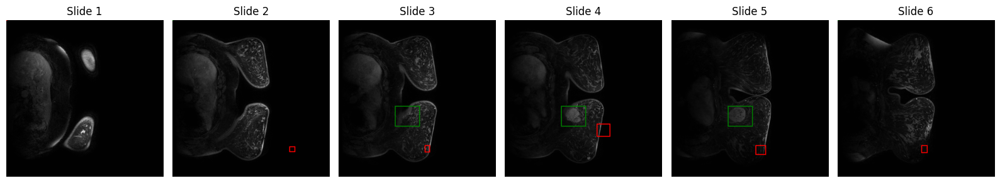

1 o'clock
7 o'clock
MEDGEMMA OCLCOK: 1.0
 GT OCLOCK 7.0

Fibroglandular Tissue: True

Patient: Breast_MRI_213
------------------------------
Findings:
Fibroglandular Tissue: True
Background Parenchymal Enhancement: True
Tumor Location (Right/Left Breast): True
Tumor Location (o'clock): False
Tumor Unifocal/Multifocal: True
Tumor Volume:
  MedGemma: 5.002 cm^3
  Ground Truth: 1369.835 cm^3
Skin Involvement: True
Chest Involvement: False
Lymphadenopathy or Suspicious Nodes Found: False

Repicking New Sample Vol


Map:   0%|          | 0/6 [00:00<?, ? examples/s]

MEDGEMMA REPORT
------------------------------

Patient: Breast_MRI_108
------------------------------
Findings:
Fibroglandular Tissue: \NA with \NA% of breast FGT
Background Parenchymal Enhancement: \NA\ with \NA%\ of FGT tissue enhanced

Left Breast: Normal.
Right Breast: 
Tumor Location: \R\, \ 12 o'clock\
Unifocal/Multifocal: Tumor is \Unifocal\
Tumor Dimensions: Tumor is 2.812 cm x 3.234 cm x 3.200 cm
Tumor Volume: \39.667\ cm^3
Skin Involvement: There is \no skin involvement\
Chest/Pec Involvement: There is \no chest involvement\
Axilla and Other: There were \no Lymphadenopathy\Suspicious Nodes\ found.


GROUND TRUTH
------------------------------
Patient: Breast_MRI_108
------------------------------
Findings:
Fibroglandular Tissue: \NA with \NA% of breast FGT
Background Parenchymal Enhancement: \NA\ with \NA%\ of FGT tissue enhanced

Left Breast: Normal.
Right Breast: 
Tumor Location: \R\, \ 11, R 9 o'clock\
Unifocal/Multifocal: Tumor is \Multifocal\
Tumor Dimensions: Tumor is 

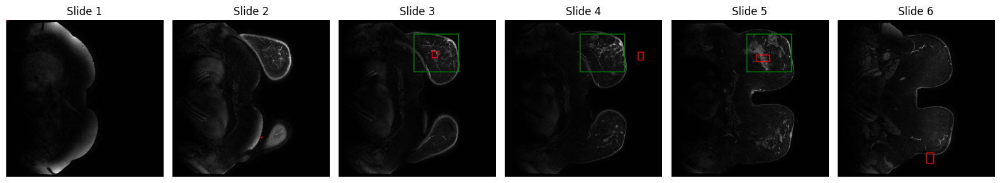

12 o'clock
11, R 9 o'clock
MEDGEMMA OCLCOK: 12.0
 GT OCLOCK 11.0

Fibroglandular Tissue: True

Patient: Breast_MRI_108
------------------------------
Findings:
Fibroglandular Tissue: True
Background Parenchymal Enhancement: True
Tumor Location (Right/Left Breast): True
Tumor Location (o'clock): False
Tumor Unifocal/Multifocal: False
Tumor Volume:
  MedGemma: 39.667 cm^3
  Ground Truth: 1195.879 cm^3
Skin Involvement: True
Chest Involvement: True
Lymphadenopathy or Suspicious Nodes Found: False

Repicking New Sample Vol


Map:   0%|          | 0/6 [00:00<?, ? examples/s]

MEDGEMMA REPORT
------------------------------

Patient: Breast_MRI_062
------------------------------
Findings:
Fibroglandular Tissue: \NA with \NA% of breast FGT
Background Parenchymal Enhancement: \NA\ with \NA%\ of FGT tissue enhanced

Left Breast: 
Tumor Location: \L\, \ 12 o'clock\
Unifocal/Multifocal: Tumor is \Unifocal\
Tumor Dimensions: Tumor is 2.529 cm x 2.529 cm x 1.650 cm
Tumor Volume: \14.178\ cm^3
Skin Involvement: There is \no skin involvement\
Chest/Pec Involvement: There is \no chest involvement\
Right Breast: Normal.
Axilla and Other: There were \no Lymphadenopathy\Suspicious Nodes\ found.


GROUND TRUTH
------------------------------
Patient: Breast_MRI_062
------------------------------
Findings:
Fibroglandular Tissue: \NA with \NA% of breast FGT
Background Parenchymal Enhancement: \NA\ with \NA%\ of FGT tissue enhanced

Tumor location in breasts unmarked. Findings can not be attributed to specific breast:
Tumor Location: \nan\, \ 3 o'clock\
Unifocal/Multifocal: Tu

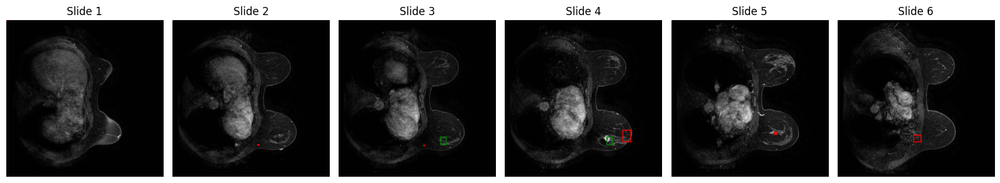

12 o'clock
3 o'clock
MEDGEMMA OCLCOK: 12.0
 GT OCLOCK 3.0

Fibroglandular Tissue: True

Patient: Breast_MRI_062
------------------------------
Findings:
Fibroglandular Tissue: True
Background Parenchymal Enhancement: True
Tumor Location (Right/Left Breast): False
Tumor Location (o'clock): False
Tumor Unifocal/Multifocal: True
Tumor Volume:
  MedGemma: 14.178 cm^3
  Ground Truth: 11.636 cm^3
Skin Involvement: True
Chest Involvement: True
Lymphadenopathy or Suspicious Nodes Found: False



Map:   0%|          | 0/7 [00:00<?, ? examples/s]

MEDGEMMA REPORT
------------------------------

Patient: Breast_MRI_059
------------------------------
Findings:
Fibroglandular Tissue: \NA with \NA% of breast FGT
Background Parenchymal Enhancement: \NA\ with \NA%\ of FGT tissue enhanced

Left Breast: Normal.
Right Breast: 
Tumor Location: \R\, \ 10 o'clock\
Unifocal/Multifocal: Tumor is \Multifocal\
Tumor Dimensions: Tumor is 2.580 cm x 2.656 cm x 3.400 cm
Tumor Volume: \35.425\ cm^3
Skin Involvement: There is \no skin involvement\
Chest/Pec Involvement: There is \no chest involvement\
Axilla and Other: There were \no Lymphadenopathy\Suspicious Nodes\ found.


GROUND TRUTH
------------------------------
Patient: Breast_MRI_059
------------------------------
Findings:
Fibroglandular Tissue: \NA with \NA% of breast FGT
Background Parenchymal Enhancement: \NA\ with \NA%\ of FGT tissue enhanced

Left Breast: 
Tumor Location: \L\, \ 12 o'clock\
Unifocal/Multifocal: Tumor is \Multifocal\
Tumor Dimensions: Tumor is 1.262 cm x 2.059 cm x 2.6

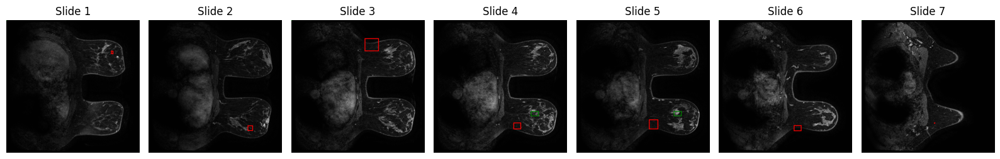

10 o'clock
12 o'clock
MEDGEMMA OCLCOK: 10.0
 GT OCLOCK 12.0

Fibroglandular Tissue: True

Patient: Breast_MRI_059
------------------------------
Findings:
Fibroglandular Tissue: True
Background Parenchymal Enhancement: True
Tumor Location (Right/Left Breast): False
Tumor Location (o'clock): False
Tumor Unifocal/Multifocal: True
Tumor Volume:
  MedGemma: 35.425 cm^3
  Ground Truth: 14.435 cm^3
Skin Involvement: True
Chest Involvement: True
Lymphadenopathy or Suspicious Nodes Found: True

Repicking New Sample Vol
Repicking New Sample Vol
Repicking New Sample Vol


Map:   0%|          | 0/6 [00:00<?, ? examples/s]

MEDGEMMA REPORT
------------------------------

Patient: Breast_MRI_133
------------------------------
Findings:
Fibroglandular Tissue: \NA with \NA% of breast FGT
Background Parenchymal Enhancement: \NA\ with \NA%\ of FGT tissue enhanced

Tumor location in breasts unmarked. Findings can not be attributed to specific breast:
Tumor Location: \nan\, \ 10, R 10 o'clock\
Unifocal/Multifocal: Tumor is \Multifocal\
Tumor Dimensions: Tumor is 2.812 cm x 3.631 cm x 4.000 cm
Tumor Volume: \54.748\ cm^3
Skin Involvement: There is \no skin involvement\
Chest/Pec Involvement: There is \no chest involvement\
Axilla and Other: There were \no Lymphadenopathy\Suspicious Nodes\ found.


GROUND TRUTH
------------------------------
Patient: Breast_MRI_133
------------------------------
Findings:
Fibroglandular Tissue: \NA with \NA% of breast FGT
Background Parenchymal Enhancement: \NA\ with \NA%\ of FGT tissue enhanced

Tumor location in breasts unmarked. Findings can not be attributed to specific breast

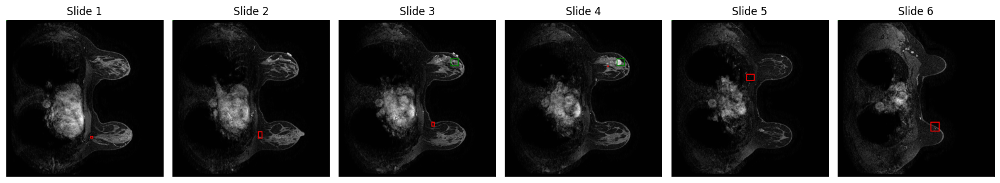

10, R 10 o'clock
o'clock
MEDGEMMA OCLCOK: 10.0
 GT OCLOCK 0

Fibroglandular Tissue: True

Patient: Breast_MRI_133
------------------------------
Findings:
Fibroglandular Tissue: True
Background Parenchymal Enhancement: True
Tumor Location (Right/Left Breast): True
Tumor Location (o'clock): False
Tumor Unifocal/Multifocal: True
Tumor Volume:
  MedGemma: 54.748 cm^3
  Ground Truth: 12.093 cm^3
Skin Involvement: True
Chest Involvement: True
Lymphadenopathy or Suspicious Nodes Found: True

Repicking New Sample Vol


Map:   0%|          | 0/6 [00:00<?, ? examples/s]

MEDGEMMA REPORT
------------------------------

Patient: Breast_MRI_001
------------------------------
Findings:
Fibroglandular Tissue: \NA with \NA% of breast FGT
Background Parenchymal Enhancement: \NA\ with \NA%\ of FGT tissue enhanced

Left Breast: Normal.
Right Breast: 
Tumor Location: \R\, \ 10 o'clock\
Unifocal/Multifocal: Tumor is \Unifocal\
Tumor Dimensions: Tumor is 2.529 cm x 2.666 cm x 3.400 cm
Tumor Volume: \39.105\ cm^3
Skin Involvement: There is \no skin involvement\
Chest/Pec Involvement: There is \no chest involvement\
Axilla and Other: There were \no Lymphadenopathy\Suspicious Nodes\ found.


GROUND TRUTH
------------------------------
Patient: Breast_MRI_001
------------------------------
Findings:
Fibroglandular Tissue: \NA with \NA% of breast FGT
Background Parenchymal Enhancement: \NA\ with \NA%\ of FGT tissue enhanced

Left Breast: 
Tumor Location: \L\, \ 9 medial o'clock\
Unifocal/Multifocal: Tumor is \Unifocal\
Tumor Dimensions: Tumor is 2.652 cm x 2.973 cm x 2

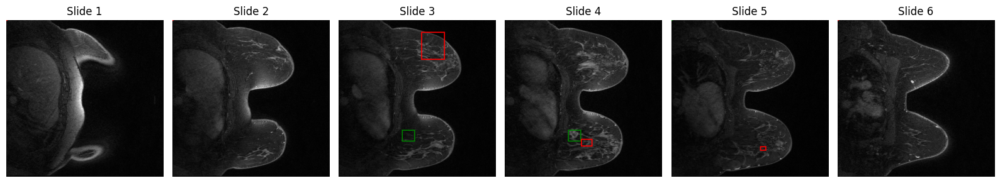

10 o'clock
9 medial o'clock
MEDGEMMA OCLCOK: 10.0
 GT OCLOCK 9.0

Fibroglandular Tissue: True

Patient: Breast_MRI_001
------------------------------
Findings:
Fibroglandular Tissue: True
Background Parenchymal Enhancement: True
Tumor Location (Right/Left Breast): False
Tumor Location (o'clock): False
Tumor Unifocal/Multifocal: True
Tumor Volume:
  MedGemma: 39.105 cm^3
  Ground Truth: 55.268 cm^3
Skin Involvement: True
Chest Involvement: True
Lymphadenopathy or Suspicious Nodes Found: True



In [ ]:
#save report into excel

saved_report_dir = '/content/drive/MyDrive/Duke_Dataset/BreastDCEDL_duke/BreastDCEDL_duke/duke_subset_nii/Saved_reports'

medgemma_reports = []
gt_report_list = []
overlay_pil_list = []
comparison_report_list = []

#figure acc proportion list
fgt_str_prop_list = []
bpe_str_prop_list = []
loc_str_prop_list =[]
oclock_str_prop_list =[]
oclock_within_1_str_prop_list = []
focal_str_prop_list =[]
volume_str_prop_list = []
volume_acc_threshold = 5 # how am i defining if acc -> as tumor size inc difference is larger lets just try ~5cm^3 for now
skin_str_prop_list  = []
chest_str_prop_list = []
axilla_str_prop_list = []


#gt features list

print(len(report_data_mapped["validation"]))
ind_list  = []
n_tabs = 25
for i in range(n_tabs):
  repeat_sample = True
  while(repeat_sample):
    ind = np.random.randint(0,len(report_data_mapped["validation"])) # rand samp
    if ind not in ind_list:
      ind_list.append(ind)
      repeat_sample = False
    else:
      print('Repicking New Sample Vol')

  val_count = len(report_data_mapped["validation"])
  if i<val_count:
    med, gt, pil = GenerateReport(i,6)

    med = med.split(f'\\')
    med[1] = med[1][:-5]
    suspicous_lymph = f'{med[19]} or {med[20]}{med[21]}'
    report_element_idx = [1,3,7,9,11,13,15,17]
    med = [med[i] for i in report_element_idx]
    med.append(suspicous_lymph)
    med[3] = med[3][1:]

    gt = gt.split(f'\\')
    pat_str = gt[0]
    gt[1] = gt[1][:-5]
    suspicous_lymph_gt = f'{gt[19]} or {gt[20]}{gt[21]}'
    gt = [gt[i] for i in report_element_idx]
    gt.append(suspicous_lymph_gt)
    gt[3] = gt[3][1:]

    # for i in range(len(med)):
    #   print(f'{i}) {med[i]}\n')
    #   print(f'{i}) {gt[i]}\n')

    #bool acc cross val
    fgt_bool = med[0]==gt[0]
    bpe_bool = med[1]==gt[1]
    loc_bool = med[2]==gt[2]
    oclock_bool = med[3]==gt[3]
    print(med[3])
    print(gt[3])
    med_clock = med[3][:2].strip()
    gt_clock = gt[3][:2].strip()

    try:
      f_med_clock = float(med_clock)
    except ValueError:
      f_med_clock = 0

    try:
      f_gt_clock = float(gt_clock)
    except ValueError:
      f_gt_clock = 0

    print(f'MEDGEMMA OCLCOK: {f_med_clock}\n GT OCLOCK {f_gt_clock}')
    o_clock_diff =  np.abs(f_med_clock - f_gt_clock)
    oclock_within_one_bool = o_clock_diff<1


    focal_bool = med[4]==gt[4]
    #eval volume within range?
    try:
      vol_med = float(med[5])
    except ValueError:
      vol_med = None

    try:
      vol_gt = float(gt[5])
    except ValueError:
      vol_gt = None

    if vol_med is not None and vol_gt is not None:
      vol_dif = vol_med-vol_gt
      vol_bool = np.abs(vol_dif)<5
    else:
      vol_bool = False


    skin_bool = med[6]==gt[6]
    chest_bool = med[7]==gt[7]
    axilla_bool = med[8]==gt[8]


    #cross eval
    fgt_str = f'\nFibroglandular Tissue: {fgt_bool}\n'
    print(fgt_str)
    bpe_str = f'Background Parenchymal Enhancement: {bpe_bool}\n'
    loc_str = f'Tumor Location (Right/Left Breast): {loc_bool}\n'
    oclock_str = f"Tumor Location (o'clock): {oclock_bool}\n"
    focal_str = f'Tumor Unifocal/Multifocal: {focal_bool}\n'
    volume_str = f'Tumor Volume:\n  MedGemma: {med[5]} cm^3\n  Ground Truth: {gt[5]} cm^3\n'
    skin_str = f'Skin Involvement: {skin_bool}\n'
    chest_str = f'Chest Involvement: {chest_bool}\n'
    axilla_str = f'Lymphadenopathy or Suspicious Nodes Found: {axilla_bool}\n'

    comparison_report = pat_str[14:-24]+fgt_str+bpe_str+loc_str+oclock_str+focal_str+volume_str+skin_str+chest_str+axilla_str

    #append cross eval to proportion lists
    fgt_str_prop_list.append(fgt_bool)
    bpe_str_prop_list.append(bpe_bool)
    loc_str_prop_list.append(loc_bool)
    oclock_str_prop_list.append(oclock_bool)
    focal_str_prop_list.append(focal_bool)
    volume_str_prop_list.append(vol_bool)
    skin_str_prop_list.append(skin_bool)
    chest_str_prop_list.append(chest_bool)
    axilla_str_prop_list.append(axilla_bool)
    oclock_within_1_str_prop_list.append(oclock_within_one_bool)

    print(comparison_report)
    medgemma_reports.append(med)
    gt_report_list.append(gt)
    comparison_report_list.append(comparison_report)
    overlay_pil_list.append(pil)


In [ ]:
#proportion analysis and calculation'
print(len(report_data_mapped["train"]))
print(f'# Count {len(fgt_str_prop_list)}')
fgt_prop = sum(fgt_str_prop_list)/len(fgt_str_prop_list) # Disclude
bpe_prop = sum(bpe_str_prop_list)/len(bpe_str_prop_list) #disclude

loc_prop = sum(loc_str_prop_list)/len(loc_str_prop_list)
oclock_prop = sum(oclock_str_prop_list) / len(oclock_str_prop_list)
focal_prop = sum(focal_str_prop_list) / len(focal_str_prop_list)
volume_prop = sum(volume_str_prop_list) / len(volume_str_prop_list)
skin_prop = sum(skin_str_prop_list) / len(skin_str_prop_list)
chest_prop = sum(chest_str_prop_list) / len(chest_str_prop_list)
axilla_prop = sum(axilla_str_prop_list) / len(axilla_str_prop_list)
oclock_within_one_prop  = sum(oclock_within_1_str_prop_list) / len(oclock_within_1_str_prop_list)

print(f"FGT: Discluded \nBPE: Discluded\nLocation (L/R): {loc_prop}\nLocation (oclock): {oclock_prop}\noclock within 1: {oclock_within_one_prop}\nUnifocal or Multifocal: {focal_prop}\nVolume within 5cm: {volume_prop}\nSkin Involvement: {skin_prop}\nChest Involvement:{chest_prop}\nLymphadenopathy or Suspicious Nodes Found: {axilla_prop}")


292
# Count 25
FGT: Discluded 
BPE: Discluded
Location (L/R): 0.48
Location (oclock): 0.12
oclock within 1: 0.12
Unifocal or Multifocal: 0.64
Volume within 5cm: 0.12
Skin Involvement: 0.96
Chest Involvement:0.96
Lymphadenopathy or Suspicious Nodes Found: 0.56


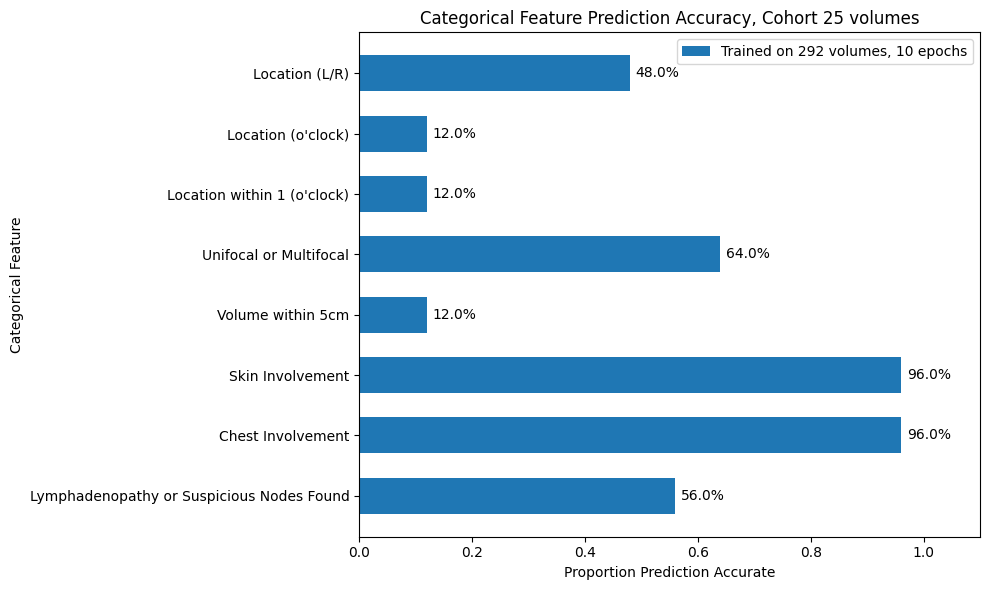

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

acc_data = {
    "category": [
        "Location (L/R)",
        "Location (o'clock)",
        "Location within 1 (o'clock)",
        "Unifocal or Multifocal",
        "Volume within 5cm",
        "Skin Involvement",
        "Chest Involvement",
        "Lymphadenopathy or Suspicious Nodes Found"
    ],
    "proportion accurate": [
        loc_prop,
        oclock_prop,
        oclock_within_one_prop,
        focal_prop,
        volume_prop,
        skin_prop,
        chest_prop,
        axilla_prop
    ]
}

categories = acc_data["category"]
plot_acc = np.array(acc_data["proportion accurate"])

fig, ax = plt.subplots(figsize=(10, 6))

y = np.arange(len(categories))

bars = ax.barh(
    y,
    plot_acc,
    height=0.6,
    label=f"Trained on {len(report_data_mapped["train"])} volumes, 10 epochs"
)

# Put the first category at the top
ax.set_yticks(y)
ax.set_yticklabels(categories)
ax.invert_yaxis()

ax.set_xlabel("Proportion Prediction Accurate")
ax.set_ylabel("Categorical Feature")

ax.set_title(
    f"Categorical Feature Prediction Accuracy, Cohort {n_tabs} volumes"
)

# Add percentage labels
for bar, value in zip(bars, plot_acc):
    ax.text(
        value + 0.01,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.1%}",
        va="center"
    )

ax.set_xlim(0, 1.1)
ax.legend()

plt.tight_layout()
plt.show()

In [ ]:
# #get rates of + in val dataset compared to train
# train_set = report_data_mapped["train"]
# val_set = report_data_mapped["validation"]

# #split into lists for each features rate

# print(train_set('g'))

#evaluate annotation boxes


In [ ]:
import re
from openpyxl import Workbook
from openpyxl.drawing.image import Image as XLImage
from openpyxl.styles import Font, Alignment, PatternFill
from openpyxl.utils import get_column_letter
from io import BytesIO


TRUE_FILL = PatternFill(start_color="C6EFCE", end_color="C6EFCE", fill_type="solid")
FALSE_FILL = PatternFill(start_color="FFC7CE", end_color="FFC7CE", fill_type="solid")


def write_comparison_report(ws, comparison_report, start_row):
    row = start_row

    for raw_line in comparison_report.split("\n"):
        line = raw_line.rstrip()

        if not line.strip():
            continue

        if set(line.strip()) == {"-"}:
            continue

        is_indented = len(raw_line) > len(raw_line.lstrip())

        if ":" in line:
            label, value = line.split(":", 1)
            label = label.strip()
            value = value.strip()
        else:
            label = line.strip()
            value = ""

        label_col = "B" if is_indented else "A"
        label_cell = ws[f"{label_col}{row}"]
        label_cell.value = label

        if is_indented:
            label_cell.font = Font(italic=True, size=10)
        elif label in ("Patient", "Findings"):
            label_cell.font = Font(bold=True, size=12)
        else:
            label_cell.font = Font(bold=False)

        if value:
            value_cell = ws[f"C{row}"]
            value_cell.value = value

            normalized = value.strip().upper()
            if normalized == "TRUE":
                value_cell.fill = TRUE_FILL
            elif normalized == "FALSE":
                value_cell.fill = FALSE_FILL

        row += 1

    return row


def make_excel_report(
    comparison_reports,
    all_overlay_plots,
    output_path=f"{saved_report_dir}/MedGemma_Reports.xlsx"
):
    wb = Workbook()
    wb.remove(wb.active)

    image_buffers = []

    for i, (comparison_report, images) in enumerate(
        zip(comparison_reports, all_overlay_plots)
    ):
        match = re.search(r"Patient:\s*(\S+)*?\]", comparison_report)
        patient_id = match.group(1) if match else f"Report_{i+1}"
        sheet_name = patient_id[:31]
        if sheet_name in wb.sheetnames:
            sheet_name = f"{patient_id[:27]}_{i+1}"

        ws = wb.create_sheet(title=sheet_name)

        ws.column_dimensions["A"].width = 32
        ws.column_dimensions["B"].width = 20
        ws.column_dimensions["C"].width = 20

        next_row = write_comparison_report(ws, comparison_report, start_row=1)

        image_start_row = next_row + 1
        ws[f"A{image_start_row}"] = "MRI SLIDES"
        ws[f"A{image_start_row}"].font = Font(bold=True, size=14)

        image_row = image_start_row + 1
        display_width = 260
        display_height = 260
        image_col_width = display_width / 7

        for slide_idx, pil_img in enumerate(images):
            img_col = slide_idx + 1

            img_buffer = BytesIO()
            if pil_img.mode != "RGB":
                pil_img = pil_img.convert("RGB")
            pil_img.save(img_buffer, format="PNG")
            img_buffer.seek(0)
            image_buffers.append(img_buffer)

            excel_img = XLImage(img_buffer)
            excel_img.width = display_width
            excel_img.height = display_height

            image_cell = f"{get_column_letter(img_col)}{image_row}"
            ws.add_image(excel_img, image_cell)

            ws.column_dimensions[get_column_letter(img_col)].width = image_col_width

        ws.row_dimensions[image_row].height = display_height * 0.75

        ws.freeze_panes = f"A{image_start_row}"

    wb.save(output_path)
    print(f"Saved Excel workbook to: {output_path}")

if n_tabs<200:
  make_excel_report(
      comparison_reports=comparison_report_list,
      all_overlay_plots=overlay_pil_list,
      output_path=f"{saved_report_dir}/MedGemma_Comparison_Reports_v2.xlsx"
  )

Saved Excel workbook to: /content/drive/MyDrive/Duke_Dataset/BreastDCEDL_duke/BreastDCEDL_duke/duke_subset_nii/Saved_reports/MedGemma_Comparison_Reports_v2.xlsx


In [ ]:
def make_excel_report(
    medgemma_reports,
    gt_reports,
    all_overlay_plots,
    output_path=f"{saved_report_dir}/MedGemma_Reports_V2.xlsx"
):
    wb = Workbook()
    wb.remove(wb.active)

    # openpyxl reads image bytes lazily at save() time, so every BytesIO buffer
    # must stay referenced until wb.save() runs or the image silently disappears.
    image_buffers = []

    TEXT_COL_SPAN = 12  # columns to merge report text across

    for i, (med_report, gt_report, images) in enumerate(
        zip(medgemma_reports, gt_reports, all_overlay_plots)
    ):
        match = re.search(r"Patient:\s*(\S+)", gt_report)
        patient_id = match.group(1) if match else f"Report_{i+1}"
        sheet_name = patient_id[:31]
        if sheet_name in wb.sheetnames:
            sheet_name = f"{patient_id[:27]}_{i+1}"

        ws = wb.create_sheet(title=sheet_name)
        last_col = get_column_letter(TEXT_COL_SPAN)

        # --- MedGemma report ---
        ws["A1"] = "MEDGEMMA REPORT"
        ws["A1"].font = Font(bold=True, size=14)

        ws.merge_cells(f"A2:{last_col}2")
        ws["A2"] = med_report
        ws["A2"].alignment = Alignment(wrap_text=True, vertical="top")
        ws.row_dimensions[2].height = 100

        # --- Ground truth ---
        ws["A4"] = "GROUND TRUTH"
        ws["A4"].font = Font(bold=True, size=14)

        ws.merge_cells(f"A5:{last_col}5")
        ws["A5"] = gt_report
        ws["A5"].alignment = Alignment(wrap_text=True, vertical="top")
        ws.row_dimensions[5].height = 100

        # --- Images ---
        image_start_row = 7
        ws[f"A{image_start_row}"] = "MRI SLIDES"
        ws[f"A{image_start_row}"].font = Font(bold=True, size=14)

        image_row = image_start_row + 1
        display_width = 260
        display_height = 260

        # openpyxl width units ≈ pixels / 7
        image_col_width = display_width / 7

        for slide_idx, pil_img in enumerate(images):
            img_col = slide_idx + 1  # one column per image, no gap/label column

            img_buffer = BytesIO()
            if pil_img.mode != "RGB":
                pil_img = pil_img.convert("RGB")
            pil_img.save(img_buffer, format="PNG")
            img_buffer.seek(0)
            image_buffers.append(img_buffer)  # prevent GC before save()

            excel_img = XLImage(img_buffer)
            excel_img.width = display_width
            excel_img.height = display_height

            image_cell = f"{get_column_letter(img_col)}{image_row}"
            ws.add_image(excel_img, image_cell)

            ws.column_dimensions[get_column_letter(img_col)].width = image_col_width

        # openpyxl row height is in points ≈ pixels * 0.75
        ws.row_dimensions[image_row].height = display_height * 0.75

        ws.freeze_panes = f"A{image_start_row}"

    wb.save(output_path)
    print(f"Saved Excel workbook to: {output_path}")

In [ ]:
# make_excel_report(medgemma_reports, gt_report_list, overlay_pil_list)

In [ ]:
# slide_count = 8
# pat_pc1_slides = GetCenterSlides(nib.load(pat['Tumor Segmentation Mask']), slide_count+2)
# pat_pc1_slides = pat_pc1_slides[1:-1] # remove first and last

# print(pat_pc1_slides)

# pc1_vol = nib.load(pat['Post Contrast 1']).get_fdata() # gets pc1 in correspondance to annotation slide markers

# fig, axes = plt.subplots(2, 3, figsize=(4*slide_count, 4*slide_count))

# for ax, z in zip(axes.ravel(), pat_pc1_slides):
#     ax.imshow(pc1_vol[:, :, z], cmap="gray")
#     ax.set_title(f"Slice {z}")
#     ax.axis("off")

# plt.tight_layout()
# plt.show()

In [ ]:
# def ReturnCroppedDataframe(img_idx, crop_paths, example=example, df=subset):
#   cur_pid = example['gt_report'][24:38]
#   #grab the right df row from cur_pid to then find idx
#   pat = df[df['Patient ID'] == cur_pid].iloc[0] # series

#   #format the correct dataloader format to run on unilateral cropped volume instead of bilateral

#   #format with post contrast 1 col and annotation box col w new volumes
#   #only include real gt if annotation isnt empty - if it is dont include as part of patient frame
#   crop_vol_pc1_path = crop_paths[img_idx]
#   crop_vol_ab_path = crop_paths[img_idx+1]

#   cropped_patient_df = pd.DataFrame({
#       'Patient ID': [cur_pid],
#       'Post Contrast 1' : [crop_vol_pc1_path],
#       'Annotation Box' : [crop_vol_ab_path],
#       })

#   #check if crop annotation is empty
#   annotation_loaded = np.load(crop_vol_ab_path)

#   if annotation_loaded.any():
#     cropped_patient_df['Ground Truth Report'] = [pat['Ground Truth Report']]

#   return cropped_patient_df

# def GetCropdata(example, df=subset):
#   #grab cropped images and run model:
#   cur_pid = example['gt_report'][24:38]
#   print(cur_pid)
#   #grab the right df row from cur_pid to then find idx
#   pat = subset[subset['Patient ID'] == cur_pid].iloc[0] # series
#   id_crop_vol , list_crop_vol = CropTo3Volumes(subset, pat.name, True)

#   # 0 = bilateral/breast only crop Post Contrast 1
#   # 1 = bilateral/breast only crop tumor annotated box
#   # 2 = left breast crop Post Contrast 1
#   # 3 = left breast crop tumor annotated box
#   # 4 = right breast crop Post Contrast 1
#   # 5 = right breast crop tumor annotated box
#   left_breast_df = ReturnCroppedDataframe(2,list_crop_vol,example,df)
#   right_breast_df = ReturnCroppedDataframe(4,list_crop_vol,example,df)

#   return left_breast_df, right_breast_df


In [ ]:
# #preprocessing of cropped patient df
# left_df,  right_df = GetCropdata(example)

# right_df


In [ ]:
# cropped_patient_dataset = DatasetDict({
#     "Cropped Left":  Dataset.from_pandas(left_df),
#     "Cropped Right":  Dataset.from_pandas(right_df),
# })

In [ ]:
# cropped_patient_data_processed = cropped_patient_dataset.map(
#     apply_preprocess,
#     remove_columns=cropped_patient_dataset["Cropped Left"].column_names
# )

# print(data_processed["Cropped Left"].features)

In [ ]:
#using einstein report ex, quantiative variables predictions (Above reports) and annotation boxes, maybe create the flexible report generation structure, for more impressions focused work?

# how to fine tune? compare the semantic similarity to the quantitatively structure reports? can't have tempalte language - or maybe rag that prev database?